# Laboratorium 6: Sterowanie zrobotyzowaną komórką produkcyjną na podstawie prognoz

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_6.ipynb)

W tym ćwiczeniu łączysz zadania zespołu produkcyjnego i analitycznego. Mała komórka produkcyjna przygotowuje dwa rodzaje karmy na dwa miesiące dostaw:

- **Protein Plus** — produkt o podwyższonej zawartości białka,
- **Budget Blend** — mieszankę ekonomiczną.

Ceny składników są niepewne, a maszyny mogą ulec awarii, jeśli nie zaplanujemy konserwacji zapobiegawczej. Połącz dane, prognozowanie, uczenie maszynowe, optymalizację, harmonogramowanie i planowanie projektu w jedną rekomendację dla produkcji.

Wykorzystamy pomysły z wcześniejszych laboratoriów:

- **Laboratorium 4**: harmonogramowanie typu job-shop, zmienne binarne zapobiegające nakładaniu się operacji i wykresy Gantta;
- **Laboratorium 5**: CPM/PERT, ścieżkę krytyczną, zapas czasu, ryzyko niedotrzymania terminu i skracanie zadań;
- przykłady programowania liniowego: dobór mieszanki i minimalizację kosztów.

Nazwy funkcji, kolumn i etykiety identyfikujące dane pozostają w kodzie po angielsku. Na przykład `chicken`, `beef`, `eggs`, `milk` i `plant_filler` oznaczają kurczaka, wołowinę, jaja, mleko i wypełniacz roślinny. Stanowiska `Mixer`, `Thermal processor`, `Packaging robot` i `Vision inspection` to mieszalnik, obróbka cieplna, robot pakujący i kontrola wizyjna. Dzięki stałym etykietom kod może korzystać z tych samych plików CSV co wersja angielska.

Lokalnie notatnik odnajdzie wspólny folder `data/`, również przy uruchomieniu z folderu `pl/`. W Colab funkcja pobierze brakujące pliki do środowiska notatnika.

## Schemat systemu

![Zrobotyzowana komórka produkcyjna połączona z prognozowaniem, oceną ryzyka awarii, planowaniem sieciowym i harmonogramowaniem](https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/master/lab_auto_6_illustration.png)

Ilustracja pokazuje cały pomysł ćwiczenia: roboty produkcyjne współpracują z systemem prognoz cen, monitorowania ryzyka awarii, planowania projektu i optymalizacji harmonogramu. Angielskie podpisy na wspólnej ilustracji odpowiadają tym samym elementom systemu.

## Co zrobisz w tym ćwiczeniu

1. Zbierzesz i uporządkujesz publiczne szeregi czasowe cen.
2. Porównasz modele prognozowania na wydzielonym okresie walidacji.
3. Wytrenujesz i ocenisz klasyfikator ryzyka awarii.
4. Dobierzesz próg decyzji na podstawie kosztu błędów, a nie tylko trafności klasyfikacji.
5. Sformułujesz i rozwiążesz liniowy problem doboru mieszanki.
6. Zbudujesz binarny model wyboru działań konserwacyjnych.
7. Dostosujesz harmonogramowanie typu job-shop do komórki produkcyjnej.
8. Połączysz czas zakończenia produkcji z planem projektu CPM/PERT.
9. Uzasadnisz plan działania w kilku scenariuszach.

## 0. Importy i konfiguracja

Notatnik działa w Google Colab i lokalnym Jupyterze. Komórka sprawdza dostępność PuLP i instaluje potrzebne biblioteki, jeśli solvera brakuje.

Wykorzystane narzędzia:

- `pathlib.Path`: obsługa ścieżek do plików w różnych środowiskach;
- `scikit-learn`: trenowanie i ocena modeli ryzyka awarii;
- `statsmodels`: prognozowanie z wykorzystaniem wygładzania wykładniczego;
- `pulp`: budowanie i rozwiązywanie modeli liniowych i binarnych;
- `networkx`: zapis sieci projektu CPM/PERT jako grafu.

### Jak działają funkcje przygotowujące pliki?

`download_if_missing(filename)` przyjmuje nazwę pliku, sprawdza folder `data/` i zwraca obiekt `Path`. Pobiera plik tylko wtedy, gdy pliku brakuje lub jest pusty. `ensure_lab6_data()` wywołuje tę funkcję dla każdej nazwy z `REQUIRED_DATA_FILES` i zwraca listę ścieżek. Te funkcje przygotowują pliki; dopiero następna część wczyta zawartość CSV do tabel.

Najpierw przeczytaj definicję, potem znajdź wywołanie `ensure_lab6_data()` na końcu komórki. Definicja zapamiętuje instrukcje, a wywołanie je wykonuje. Argument domyślny `data_dir=DATA_DIR` korzysta z konfiguracji, ale można podać inny folder w wywołaniu z nazwanym argumentem.

In [33]:
import sys
# Odinstalowanie i ponowna czysta instalacja pulp w celu wyeliminowania konfliktów bibliotek
!{sys.executable} -m pip uninstall -y pulp
!{sys.executable} -m pip install "pulp>=2.8,<3.0"
from __future__ import annotations
import pulp
import pandas as pd
print("Zainstalowana wersja PuLP:", pulp.__version__)

# Sprawdź solver; nowa sesja Colab może wymagać instalacji bibliotek.
try:
    import pulp
except ModuleNotFoundError:
    %pip install "pulp>=3.3,<4" pandas numpy matplotlib networkx scikit-learn statsmodels
    import pulp

import math
import re
import urllib.error
import urllib.request
import warnings
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pulp

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing

RANDOM_SEED = 42
# Ustal ziarno losowania, aby kolejne uruchomienia używały tej samej próbki danych.
np.random.seed(RANDOM_SEED)
warnings.filterwarnings("ignore", category=FutureWarning)

# Użyj danych z repozytorium, także przy uruchomieniu z folderu pl/.
# W Colab brakujący folder data/ zostanie utworzony podczas pobierania.
DATA_DIR = Path("data")
if not DATA_DIR.is_dir() and Path("../data").is_dir():
    DATA_DIR = Path("../data")
TARGET_MONTHS = [pd.Timestamp("2026-06-01"), pd.Timestamp("2026-09-01")]
TECHNICIAN_TIME_LIMIT_MIN = 120
MAINTENANCE_BUDGET = 1200

# Po otwarciu samego notatnika w Colab pliki repozytorium nie są
# automatycznie kopiowane do /content. Ta funkcja pobiera potrzebne dane,
# gdy ich brakuje. Jeśli wcześniej sklonujesz repozytorium, użyje lokalnych plików.
GITHUB_RAW_BASES = [
    "https://raw.githubusercontent.com/AdoHaha/automation_robotics_lab/master",
]

REQUIRED_DATA_FILES = [
    "lab6_orders.csv",
    "lab6_ingredients.csv",
    "lab6_stations.csv",
    "lab6_routes.csv",
    "lab6_maintenance_options.csv",
    "lab6_price_fallback.csv",
    "sensor_readings_timeseries.csv",
]


def download_if_missing(filename, data_dir=DATA_DIR, raw_bases=GITHUB_RAW_BASES):
    '''Zwróć ścieżkę pliku lokalnego; pobierz plik, jeśli go brakuje.

    Argumenty:
        filename: Nazwa pliku CSV bez nazwy folderu.
        data_dir: Obiekt Path folderu danych; domyślnie DATA_DIR.
        raw_bases: Lista głównych adresów GitHub raw; domyślnie GITHUB_RAW_BASES.

    Wynik:
        Path wskazujący niepusty plik. Przy pobieraniu wyświetla adres URL.
        Zgłasza FileNotFoundError, gdy nie można znaleźć ani pobrać pliku.
    '''
    # Utwórz folder, a następnie sprawdź, czy istnieje już niepusty plik.
    data_dir.mkdir(parents=True, exist_ok=True)
    target = data_dir / filename
    if target.exists() and target.stat().st_size > 0:
        return target

    last_error = None
    for raw_base in raw_bases:
        # Każdy adres repozytorium udostępnia tę samą względną ścieżkę data/nazwa_pliku.
        url = f"{raw_base}/data/{filename}"
        try:
            print(f"Pobieranie pliku {filename} z adresu {url}")
            urllib.request.urlretrieve(url, target)
            if target.exists() and target.stat().st_size > 0:
                return target
        except (urllib.error.URLError, OSError) as exc:
            last_error = exc

    raise FileNotFoundError(
        f"Nie udało się znaleźć ani pobrać pliku {filename}. "
        'Sklonuj repozytorium lub prześlij folder data/, zanim przejdziesz dalej.'
    ) from last_error


def ensure_lab6_data():
    '''Zapewnij lokalne pliki dla wszystkich nazw z REQUIRED_DATA_FILES.

    Korzysta z download_if_missing i jego domyślnego folderu oraz adresów.
    Zwraca listę obiektów Path; zgłasza błąd, jeśli nie można uzyskać pliku.
    '''
    # Wywołaj funkcję dla każdego pliku; zbierz zwrócone ścieżki w listę.
    return [download_if_missing(filename) for filename in REQUIRED_DATA_FILES]


ensure_lab6_data()

Found existing installation: PuLP 2.9.0
Uninstalling PuLP-2.9.0:
  Successfully uninstalled PuLP-2.9.0
  Using cached PuLP-2.9.0-py3-none-any.whl.metadata (5.4 kB)
Using cached PuLP-2.9.0-py3-none-any.whl (17.7 MB)
Zainstalowana wersja PuLP: 2.9.0


[PosixPath('data/lab6_orders.csv'),
 PosixPath('data/lab6_ingredients.csv'),
 PosixPath('data/lab6_stations.csv'),
 PosixPath('data/lab6_routes.csv'),
 PosixPath('data/lab6_maintenance_options.csv'),
 PosixPath('data/lab6_price_fallback.csv'),
 PosixPath('data/sensor_readings_timeseries.csv')]

## 1. Dane opisujące produkcję

Tabele definiują problem produkcyjny. Skład odżywczy jest uproszczony na potrzeby ćwiczenia; nie traktuj go jako rzeczywistej receptury.

Sprawdź znaczenie tabel:

- `orders`: co, ile i na kiedy trzeba wyprodukować;
- `ingredients`: skład odżywczy i dopuszczalne udziały składników;
- `routes`: kolejność stanowisk dla każdego produktu;
- `stations`: maszyna przypisana do stanowiska;
- `maintenance_options`: czas, koszt i korzyść z konserwacji zapobiegawczej.

In [34]:
# Path / nazwa_pliku łączy ścieżkę z nazwą; parse_dates odczytuje daty.
orders = pd.read_csv(DATA_DIR / "lab6_orders.csv", parse_dates=["target_month"])
ingredients = pd.read_csv(DATA_DIR / "lab6_ingredients.csv")
stations = pd.read_csv(DATA_DIR / "lab6_stations.csv")
routes = pd.read_csv(DATA_DIR / "lab6_routes.csv")
maintenance_options = pd.read_csv(DATA_DIR / "lab6_maintenance_options.csv")

display(orders)
display(ingredients)
display(routes)
display(maintenance_options)

,product,target_month,demand_kg,due_min,min_protein,min_fat,max_moisture
0,Protein Plus,2026-06-01,420,430,0.32,0.10,0.68
1,Budget Blend,2026-06-01,620,430,0.24,0.08,0.72
2,Protein Plus,2026-09-01,520,500,0.32,0.10,0.68
3,Budget Blend,2026-09-01,700,500,0.24,0.08,0.72


,ingredient,protein,fat,moisture,min_share,max_share,fallback_cost_per_kg
0,chicken,0.380,0.090,0.64,0.10,0.60,6.95
1,beef,0.340,0.170,0.58,0.00,0.45,9.60
2,eggs,0.130,0.110,0.76,0.00,0.25,5.40
3,milk,0.034,0.033,0.88,0.00,0.20,1.15
4,plant_filler,0.160,0.030,0.10,0.05,0.35,1.05


,product,operation,station,base_duration_min
0,Protein Plus,1,Mixer,35
1,Protein Plus,2,Thermal processor,50
2,Protein Plus,3,Packaging robot,30
3,Protein Plus,4,Vision inspection,15
4,Budget Blend,1,Mixer,30
5,Budget Blend,2,Packaging robot,28
6,Budget Blend,3,Vision inspection,12


,machine_id,station,service_time_min,service_cost,failure_cost,risk_reduction
0,1,Mixer,45,450,4000,0.70
1,2,Thermal processor,60,700,7000,0.75
2,3,Packaging robot,50,600,5500,0.70
3,4,Vision inspection,35,350,3000,0.65


In [35]:
print("=== Analiza danych do Zadania 1 ===")
# 1. Stanowisko wąskiego gardła (suma bazowych czasów obróbki dla wszystkich produktów)
bottleneck_check = routes.groupby('station')['base_duration_min'].sum().sort_values(ascending=False)
print("Suma bazowych czasów obróbki na stanowiskach:")
display(bottleneck_check)

# 2. Wymagania składu produktów
print("\nWymagania składu produktów:")
display(orders[['product', 'min_protein', 'min_fat', 'max_moisture']].drop_duplicates())

# 3. Koszty i korzyści konserwacji
maintenance_options['expected_benefit_ratio'] = (maintenance_options['failure_cost'] * maintenance_options['risk_reduction']) / maintenance_options['service_cost']
print("\nAnaliza opcji konserwacji (stosunek unikniętej straty do kosztu):")
display(maintenance_options.sort_values(by='expected_benefit_ratio', ascending=False))

=== Analiza danych do Zadania 1 ===
Suma bazowych czasów obróbki na stanowiskach:


,base_duration_min
station,
Mixer,65
Packaging robot,58
Thermal processor,50
Vision inspection,27



Wymagania składu produktów:


,product,min_protein,min_fat,max_moisture
0,Protein Plus,0.32,0.10,0.68
1,Budget Blend,0.24,0.08,0.72



Analiza opcji konserwacji (stosunek unikniętej straty do kosztu):


,machine_id,station,service_time_min,service_cost,failure_cost,risk_reduction,expected_benefit_ratio
1,2,Thermal processor,60,700,7000,0.75,7.500000
2,3,Packaging robot,50,600,5500,0.70,6.416667
0,1,Mixer,45,450,4000,0.70,6.222222
3,4,Vision inspection,35,350,3000,0.65,5.571429


### Zadanie 1 — odczytaj dane systemu

**Odpowiedzi na pytania bazujące na analizie danych wejściowych:**

1. **Które stanowisko może być wąskim gardłem?**
   Mieszalnik (`Mixer`), ponieważ ma najwyższą sumaryczną wartość bazowych czasów obróbki dla wszystkich produktów wynoszącą **65 minut** (w porównaniu do 58 min dla robota pakującego, 50 min dla obróbki cieplnej i 27 min dla kontroli wizyjnej).

2. **Który produkt ma bardziej wymagające ograniczenia składu?**
   `Protein Plus`. Wymaga on wysokiej minimalnej zawartości białka (**32%**) oraz ograniczenia wilgotności do maksymalnie **68%**, co zmusza model do używania droższych i bogatszych w białko składników (kurczak i wołowina), podczas gdy `Budget Blend` wymaga tylko 24% białka i dopuszcza do 72% wilgotności.

3. **Która konserwacja wydaje się kosztowna, ale może przynieść dużą korzyść?**
   Konserwacja stanowiska **Thermal processor (maszyna nr 2)**. Koszt usługi wynosi wprawdzie aż 700 jednostek, ale pozwala uniknąć potencjalnej straty z tytułu awarii rzędu **7000 jednostek** przy redukcji ryzyka o **75%** (najwyższy wskaźnik benefit ratio wynoszący **7.5**).

## 2. Dane o cenach składników z internetu

Źródłem aktualnych danych jest [FRED](https://fred.stlouisfed.org/), portal danych ekonomicznych Federal Reserve Economic Data.

Zacznij od [kategorii surowców FRED](https://fred.stlouisfed.org/categories/32217) lub wyszukiwarki. Przykład: seria [ceny piersi kurczaka bez kości za funt](https://fred.stlouisfed.org/series/APU0000FF1101) ma identyfikator `APU0000FF1101`.

Znajdź i sprawdź porównywalne miesięczne szeregi cen wołowiny, jaj i mleka. Kod zawiera przykładowe identyfikatory, ale samodzielnie zweryfikuj opis serii i jednostki.

| Składnik w kodzie | Twoje zadanie | Jednostka do sprawdzenia |
|---|---|---|
| chicken — kurczak | przykład: `APU0000FF1101` | USD/lb, czyli USD za funt |
| beef — wołowina | znajdź/sprawdź serię mięsa mielonego | USD/lb |
| eggs — jaja | znajdź/sprawdź serię cen jaj | USD/dozen, czyli USD za tuzin |
| milk — mleko | znajdź/sprawdź serię mleka pełnego | USD/gallon, czyli USD za galon |

Plik `data/lab6_price_fallback.csv` zawiera zapasowe dane do pracy bez połączenia z FRED.

Szereg publiczny rzadko ma jednostkę potrzebną w modelu. Przed optymalizacją przelicz ceny za funt, galon lub tuzin na wspólną jednostkę: koszt za kg w umownej walucie ćwiczenia.

### Funkcje wczytujące: jeden składnik, potem wspólna tabela

`load_fred_series` przyjmuje identyfikator serii, etykietę składnika, tabelę zapasową i przełącznik `use_live`. Odczytuje daty oraz ceny, przelicza jednostki i zwraca kolumny `date`, `ingredient`, `cost_per_kg`, `source`. Jeżeli pobranie nie powiedzie się, zwraca zapasowe wiersze danego składnika.

`load_price_history(use_live=True)` wywołuje tę funkcję dla pozycji z `fred_series`, dodaje zapasowe ceny wypełniacza i łączy tabele przez `pd.concat`. Wywołanie `load_price_history(use_live=False)` korzysta z dostarczonej historii bez pobierania aktualnych cen. To zwrócona tabela będzie wejściem do prognozowania.

Na początek używamy `use_live=False`: dostarczona historia pasuje do ustalonych miesięcy zamówień. W eksperymencie z aktualnymi cenami zmień przełącznik na `True`. Sprawdź wtedy ostatnie daty obserwacji i ustaw późniejsze miesiące zarówno w `TARGET_MONTHS`, jak i w kolumnie `orders["target_month"]`. Prognoza przyszłości wymaga terminów późniejszych od całej użytej historii.

In [36]:
# Identyfikatory FRED wskazują publiczne szeregi miesięcznych cen.
# Identyfikator ceny kurczaka podano jako przykład. Sprawdź lub zastąp pozostałe,
# korzystając samodzielnie z wyszukiwarki FRED.
fred_series = {
    "beef": "APU0000703112",
    "eggs": "APU0000708111",
    "milk": "APU0000709112",
    "chicken": "APU0000FF1101",
}

unit_conversions = pd.DataFrame([
    {"ingredient": "beef", "fred_unit": "USD/lb", "conversion_to_cost_per_kg": 2.20462},
    {"ingredient": "chicken", "fred_unit": "USD/lb", "conversion_to_cost_per_kg": 2.20462},
    {"ingredient": "eggs", "fred_unit": "USD/dozen", "conversion_to_cost_per_kg": 1 / 0.68},
    {"ingredient": "milk", "fred_unit": "USD/gallon", "conversion_to_cost_per_kg": 1 / 3.90},
    {"ingredient": "plant_filler", "fred_unit": 'początkowy koszt/kg z danych lokalnych', "conversion_to_cost_per_kg": 1.0},
])

fallback_prices = pd.read_csv(DATA_DIR / "lab6_price_fallback.csv", parse_dates=["date"])


def load_fred_series(series_id, ingredient, fallback_df, use_live=True):
    '''Zwróć miesięczne ceny jednego składnika we wspólnej jednostce koszt/kg.

    Argumenty:
        series_id: Tekstowy identyfikator serii FRED.
        ingredient: Etykieta z unit_conversions i fallback_df.
        fallback_df: Tabela z date, ingredient, cost_per_kg oraz source.
        use_live: True (domyślnie) pobiera FRED; False wybiera dane zapasowe.

    Wynik:
        DataFrame z date, ingredient, cost_per_kg, source. Przy danych bieżących
        korzysta z globalnej tabeli unit_conversions. W razie błędu wyświetla
        przyczynę i zwraca kopię zapasowych wierszy składnika.
    '''
    if not use_live:
        return fallback_df[fallback_df["ingredient"] == ingredient].copy()

    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    try:
        # FRED dostarcza kolumnę dat i cen; ujednolić trzeba ich nazwy.
        raw = pd.read_csv(url)
        date_col = raw.columns[0]
        value_col = raw.columns[1]
        df = raw.rename(columns={date_col: "date", value_col: "raw_value"})
        df["date"] = pd.to_datetime(df["date"])
        df["raw_value"] = pd.to_numeric(df["raw_value"], errors="coerce")  # Znaczniki brakujących danych zamieniają się w NaN.
        df = df.dropna(subset=["raw_value"])

        # Przelicz oryginalną jednostkę FRED na wspólną jednostkę modelu LP.
        multiplier = unit_conversions.set_index("ingredient").loc[
            ingredient, "conversion_to_cost_per_kg"
        ]
        df["cost_per_kg"] = df["raw_value"] * multiplier
        df["ingredient"] = ingredient
        df["source"] = f"FRED:{series_id}"
        return df[["date", "ingredient", "cost_per_kg", "source"]]
    except Exception as exc:
        print(f"Używam danych zastępczych dla {ingredient}: {exc}")
        return fallback_df[fallback_df["ingredient"] == ingredient].copy()


def load_price_history(use_live=True):
    '''Połącz historie składników w jedną tabelę uporządkowaną według dat.

    Argumenty:
        use_live: True (domyślnie) próbuje pobrać FRED; False używa danych zapasowych.

    Wynik:
        DataFrame z date, ingredient, cost_per_kg, source. Korzysta z fred_series,
        fallback_prices i load_fred_series. Wypełniacz zawsze ma historię zapasową.
    '''
    # concat łączy listę osobnych tabel w jedną tabelę.
    frames = [
        load_fred_series(series_id, ingredient, fallback_prices, use_live=use_live)
        for ingredient, series_id in fred_series.items()
    ]
    frames.append(fallback_prices[fallback_prices["ingredient"] == "plant_filler"].copy())
    prices = pd.concat(frames, ignore_index=True)
    prices = prices.sort_values(["ingredient", "date"])
    return prices


# Stała historia zapewnia powtarzalny punkt wyjścia dla podanych zamówień.
price_history = load_price_history(use_live=False)
price_history.groupby("ingredient").tail(3)

,date,ingredient,cost_per_kg,source
93,2025-10-01,beef,12.990,synthetic fallback for offline teaching
94,2025-11-01,beef,12.421,synthetic fallback for offline teaching
95,2025-12-01,beef,12.882,synthetic fallback for offline teaching
381,2025-10-01,chicken,8.733,synthetic fallback for offline teaching
382,2025-11-01,chicken,9.309,synthetic fallback for offline teaching
383,2025-12-01,chicken,9.217,synthetic fallback for offline teaching
189,2025-10-01,eggs,7.205,synthetic fallback for offline teaching
190,2025-11-01,eggs,7.288,synthetic fallback for offline teaching
191,2025-12-01,eggs,7.046,synthetic fallback for offline teaching
285,2025-10-01,milk,1.246,synthetic fallback for offline teaching


In [37]:
print("=== Dane do Zadania 2 (Przeliczenia jednostek FRED) ===")
display(unit_conversions)

=== Dane do Zadania 2 (Przeliczenia jednostek FRED) ===


,ingredient,fred_unit,conversion_to_cost_per_kg
0,beef,USD/lb,2.204620
1,chicken,USD/lb,2.204620
2,eggs,USD/dozen,1.470588
3,milk,USD/gallon,0.256410
4,plant_filler,początkowy koszt/kg z danych lokalnych,1.000000


### Zadanie 2 — udokumentuj jednostki

| Składnik | Seria FRED | Pierwotna jednostka FRED | Mnożnik do cost_per_kg | Docelowa jednostka | Opis przeliczenia |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Beef (Wołowina)** | `APU0000703112` | USD / lb (funt) | **2.20462** | USD / kg | 1 kg ≈ 2.20462 funta |
| **Chicken (Kurczak)** | `APU0000FF1101` | USD / lb (funt) | **2.20462** | USD / kg | 1 kg ≈ 2.20462 funta |
| **Eggs (Jaja)** | `APU0000708111` | USD / dozen (tuzin) | **1.470588** (1 / 0.68) | USD / kg | Przyjęto wagę tuzina jaj jako 0.68 kg |
| **Milk (Mleko)** | `APU0000709112` | USD / gallon (galon) | **0.256410** (1 / 3.90) | USD / kg | Przyjęto wagę galonu mleka jako 3.90 kg |
| **Plant filler** | *Lokalne* | USD / kg | **1.000000** | USD / kg | Bez zmian (dane lokalne) |

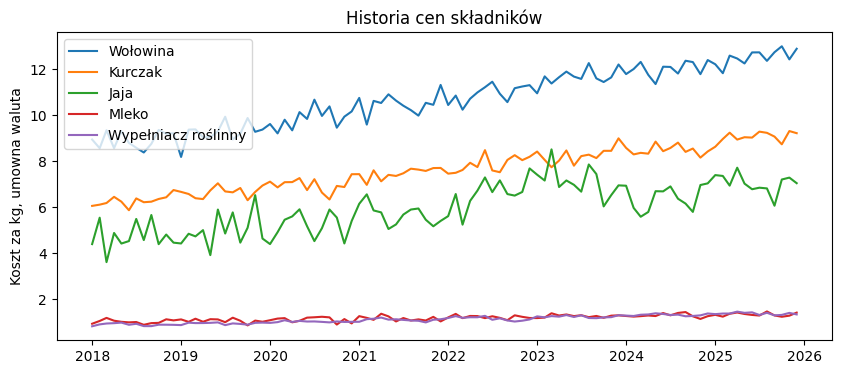

In [38]:
# Pogrupuj wiersze według składnika i porównaj historie cen na wspólnych osiach.
# Słownik tłumaczy etykiety wykresu; klucze tabeli pozostają bez zmian.
ingredient_labels = {"beef": "Wołowina", "chicken": "Kurczak", "eggs": "Jaja", "milk": "Mleko", "plant_filler": "Wypełniacz roślinny"}
fig, ax = plt.subplots(figsize=(10, 4))
for ingredient, group in price_history.groupby("ingredient"):
    ax.plot(group["date"], group["cost_per_kg"], label=ingredient_labels.get(ingredient, ingredient))
ax.set_title('Historia cen składników')
ax.set_ylabel('Koszt za kg, umowna waluta')
ax.legend()
plt.show()

## 3. Prognozowanie

Wydziel okres walidacji i porównaj modele zamiast kończyć analizę na jednej prognozie.

Porównamy:

- sezonową prognozę naiwną;
- prosty trend liniowy;
- wygładzanie wykładnicze z `statsmodels`.

Narzędzie: `statsmodels.tsa.holtwinters.ExponentialSmoothing`.

Znaczenie metod:

- **sezonowa naiwna**: „następny czerwiec będzie podobny do poprzedniego czerwca”;
- **trend liniowy**: „kontynuujemy oszacowany kierunek zmian”;
- **wygładzanie wykładnicze**: łączymy poziom, trend i sezonowość roczną.

Zachowaj ostatnie 12 miesięcy jako dane walidacyjne. Sprawdź, czy bardziej złożony model rzeczywiście zmniejsza błąd.

### Prześledź funkcje prognozowania krok po kroku

`y` jest obiektem pandas **Series**: jedną kolumną cen uporządkowanych według miesięcy. `train_test_split_series` zwraca dwie serie: wcześniejsze obserwacje do trenowania i ostatnie `test_size` obserwacji do walidacji. `.iloc` wybiera według pozycji, więc zachowujemy kolejność czasu.

Trzy funkcje prognozujące przyjmują `train` i `horizon` (liczbę przyszłych miesięcy), a zwracają serię prognoz. Prognoza naiwna powtarza ostatni cykl roczny; trend przedłuża dopasowaną prostą; wygładzanie estymuje poziom, trend i sezonowość, a przy nieudanym dopasowaniu korzysta z trendu liniowego.

`mape` zwraca błąd jako ułamek: 0.10 oznacza 10%. `evaluate_forecasters(price_df, ingredient)` wybiera składnik, buduje indeks miesięczny, uzupełnia brakujące miesiące i porównuje prognozy z odłożonymi obserwacjami. Wynikiem jest tabela MAE i MAPE. Prześledź: tabela wejściowa → seria miesięczna → podział → prognozy → tabela błędów.

In [39]:
def train_test_split_series(y, test_size=12):
    '''Podziel miesięczny szereg cen na dane treningowe i walidacyjne.

    Argumenty:
        y: Liczbowa seria pandas uporządkowana według miesięcy.
        test_size: Liczba końcowych obserwacji do walidacji; domyślnie 12.

    Wynik:
        Para (train, test) zachowująca indeks i jednostki cen. Wymaga więcej
        niż test_size + 12 obserwacji; inaczej zgłasza ValueError.
    '''
    if len(y) <= test_size + 12:
        raise ValueError('Potrzebna jest dłuższa historia do wydzielenia 12 miesięcy walidacji.')
    return y.iloc[:-test_size], y.iloc[-test_size:]  # Podziel dane na wcześniejsze wiersze i końcowy okres walidacyjny.


def seasonal_naive_forecast(train, horizon, season_length=12):
    '''Powtórz ostatni obserwowany cykl sezonowy jako prognozę cen.

    Argumenty:
        train: Uporządkowana seria cen, co najmniej season_length obserwacji.
        horizon: Liczba przyszłych obserwacji do przewidzenia.
        season_length: Liczba obserwacji w cyklu; domyślnie 12 dla danych miesięcznych.

    Wynik:
        Series z horizon cenami w jednostkach wejścia, z indeksem od zera.
    '''
    # Użyj ostatniej wartości z tego samego miesiąca cyklu sezonowego.
    # Dla danych miesięcznych i season_length=12 prognoza marca korzysta z ubiegłego marca.
    values = [train.iloc[-season_length + (h % season_length)] for h in range(horizon)]
    return pd.Series(values)


def drift_forecast(train, horizon):
    '''Przedłuż trend liniowy dopasowany do obserwowanych cen.

    Argumenty:
        train: Liczbowa seria cen uporządkowana według miesięcy.
        horizon: Liczba przyszłych miesięcy do przewidzenia.

    Wynik:
        Series z horizon cenami w jednostkach wejścia, z indeksem od zera.
    '''
    # Dopasuj prostą do danych historycznych i przedłuż ją w przyszłość.
    x = np.arange(len(train))
    coef = np.polyfit(x, train.values, deg=1)  # Dopasuj nachylenie i wyraz wolny do indeksów obserwacji i cen.
    future_x = np.arange(len(train), len(train) + horizon)
    return pd.Series(np.polyval(coef, future_x))


def exponential_smoothing_forecast(train, horizon):
    '''Prognozuj ceny z addytywnym trendem i sezonowością roczną.

    Argumenty:
        train: Miesięczna seria cen do dopasowania modelu wygładzania.
        horizon: Liczba przyszłych miesięcy do przewidzenia.

    Wynik:
        Series z horizon cenami i indeksem od zera. Przy nieudanym dopasowaniu
        lub prognozowaniu zwraca drift_forecast(train, horizon) w tych samych jednostkach.
    '''
    try:
        # Addytywny trend i sezonowość to przejrzysty punkt wyjścia.
        model = ExponentialSmoothing(
            train,
            trend="add",
            seasonal="add",
            seasonal_periods=12,
            initialization_method="estimated",
        )
        fit = model.fit(optimized=True)  # Oszacuj parametry wygładzania na danych historycznych.
        return pd.Series(fit.forecast(horizon).values)
    except Exception:
        # Użyj modelu zastępczego, jeśli nie uda się dopasować wygładzania.
        return drift_forecast(train, horizon)


def mape(y_true, y_pred):
    '''Oblicz średni bezwzględny błąd procentowy jako ułamek, pomijając zera.

    Argumenty:
        y_true: Ceny rzeczywiste, w tej samej kolejności i liczbie co y_pred.
        y_pred: Ceny przewidywane w tych samych jednostkach.

    Wynik:
        float, np. 0.10 oznacza 10% błędu. Zera w y_true pomija, by nie dzielić
        przez zero; jeśli wszystkie ceny są zerowe, pusta średnia wynosi NaN.
    '''
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    mask = y_true != 0  # Uwzględnij tylko wiersze, dla których mianownik błędu procentowego jest dodatni.
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])))


def evaluate_forecasters(price_df, ingredient):
    '''Porównaj trzy metody na ostatnich 12 miesiącach obserwacji.

    Argumenty:
        price_df: Tabela z ingredient, date i liczbową kolumną cost_per_kg.
        ingredient: Etykieta historii do oceny.

    Wynik:
        Wiersz na model: ingredient, model, MAE (koszt/kg), MAPE (ułamek).
        Korzysta z funkcji podziału i prognozowania. Brakujące wartości miesięczne
        są interpolowane przed podziałem.
    '''
    # Dla każdego składnika uporządkuj miesiące, podziel historię i prognozuj okres walidacyjny.
    series = (
        price_df[price_df["ingredient"] == ingredient]
        .sort_values("date")
        .set_index("date")["cost_per_kg"]
        .asfreq("MS")
        .interpolate()
    )
    train, test = train_test_split_series(series, test_size=12)
    # Każda prognoza ma tyle wartości, ile miesięcy w okresie walidacyjnym.
    predictions = {
        "seasonal_naive": seasonal_naive_forecast(train, len(test)),
        "drift": drift_forecast(train, len(test)),
        "exp_smoothing": exponential_smoothing_forecast(train, len(test)),
    }
    rows = []
    for model_name, pred in predictions.items():
        # Porównuj pozycje: pierwszą prognozę z pierwszym miesiącem walidacji itd.
        rows.append({
            "ingredient": ingredient,
            "model": model_name,
            "MAE": float(np.mean(np.abs(test.values - pred.values))),
            "MAPE": mape(test.values, pred.values),
        })
    return pd.DataFrame(rows)


forecast_scores = pd.concat(
    [evaluate_forecasters(price_history, ingredient) for ingredient in ingredients["ingredient"]],
    ignore_index=True,
)
forecast_scores.sort_values(["ingredient", "MAE"])

,ingredient,model,MAE,MAPE
5,beef,exp_smoothing,0.183264,0.014829
4,beef,drift,0.200488,0.016274
3,beef,seasonal_naive,0.539500,0.043033
1,chicken,drift,0.184703,0.020350
2,chicken,exp_smoothing,0.216741,0.023909
0,chicken,seasonal_naive,0.576250,0.063057
7,eggs,drift,0.434591,0.064091
8,eggs,exp_smoothing,0.440411,0.062839
6,eggs,seasonal_naive,0.656333,0.090385
10,milk,drift,0.062070,0.046455


### Od porównania metod do prognoz cen

`forecast_targets(price_df, target_months)` zwraca wiersz dla każdego składnika i miesiąca dostawy. Korzysta z etykiet w `ingredients`, wybiera metodę z najmniejszym MAE, dopasowuje ją do pełnej historii i odczytuje prognozę dla każdego terminu. Daty `target_months` muszą być późniejsze niż ostatnia obserwacja każdego składnika. `low_cost` i `high_cost` to ceny scenariuszowe uzyskane przez przemnożenie prognozy przez 0.90 i 1.15. Mają jednostkę koszt/kg; nie są statystycznymi przedziałami ufności.

Wywołanie zapisuje tabelę jako `forecast_prices`. Modele LP wybiorą z niej ceny według składnika i miesiąca. Prześledź `horizon` (jak daleko prognozujemy) i `step` (którą prognozę wybieramy) w pętli.

In [40]:
def forecast_targets(price_df, target_months):
    '''Prognozuj ceny każdego składnika na zadane miesiące dostaw.

    Argumenty:
        price_df: Tabela z ingredient, date i cost_per_kg.
        target_months: Niepusta lista miesięcznych Timestamp późniejszych od każdej historii.

    Wynik:
        DataFrame z ingredient, target_month, forecast_cost, low_cost, high_cost,
        selected_model, validation_MAE. Ceny w jednostkach koszt/kg z historii;
        low/high to ceny scenariuszowe: 0.90/1.15 razy prognoza, również w koszt/kg. Korzysta z globalnej tabeli
        ingredients i funkcji prognozujących.
    '''
    rows = []
    for ingredient in ingredients["ingredient"]:
        series = (
            price_df[price_df["ingredient"] == ingredient]
            .sort_values("date")
            .set_index("date")["cost_per_kg"]
            .asfreq("MS")
            .interpolate()
        )
        # Wybierz model o najniższym MAE w walidacji dla danego składnika.
        scores = evaluate_forecasters(price_df, ingredient)
        selected = scores.sort_values("MAE").iloc[0]
        last_date = series.index.max()
        # Różnica okresów daje liczbę miesięcy; prognozuj aż do ostatniego terminu dostawy.
        horizon = max((month.to_period("M") - last_date.to_period("M")).n for month in target_months)

        # Dopasuj wybrany model do całej historii i prognozuj miesiące dostaw.
        if selected["model"] == "seasonal_naive":
            pred = seasonal_naive_forecast(series, horizon)
        elif selected["model"] == "drift":
            pred = drift_forecast(series, horizon)
        else:
            pred = exponential_smoothing_forecast(series, horizon)

        for month in target_months:
            step = (month.to_period("M") - last_date.to_period("M")).n
            # step=1 oznacza pierwszy przyszły miesiąc, zapisany pod indeksem 0.
            forecast_cost = float(max(pred.iloc[step - 1], 0.01))
            rows.append({
                "ingredient": ingredient,
                "target_month": month,
                "forecast_cost": forecast_cost,
                "low_cost": 0.90 * forecast_cost,
                "high_cost": 1.15 * forecast_cost,
                "selected_model": selected["model"],
                "validation_MAE": selected["MAE"],
            })
    return pd.DataFrame(rows)


forecast_prices = forecast_targets(price_history, TARGET_MONTHS)
forecast_prices

,ingredient,target_month,forecast_cost,low_cost,high_cost,selected_model,validation_MAE
0,chicken,2026-06-01,9.368590,8.431731,10.773878,drift,0.184703
1,chicken,2026-09-01,9.466145,8.519530,10.886067,drift,0.184703
2,beef,2026-06-01,13.181540,11.863386,15.158771,exp_smoothing,0.183264
3,beef,2026-09-01,13.093301,11.783971,15.057297,exp_smoothing,0.183264
4,eggs,2026-06-01,7.542218,6.787996,8.673551,drift,0.434591
5,eggs,2026-09-01,7.630055,6.867050,8.774564,drift,0.434591
6,milk,2026-06-01,1.393367,1.254030,1.602372,drift,0.062070
7,milk,2026-09-01,1.404494,1.264045,1.615168,drift,0.062070
8,plant_filler,2026-06-01,1.492116,1.342904,1.715933,exp_smoothing,0.033905
9,plant_filler,2026-09-01,1.403465,1.263119,1.613985,exp_smoothing,0.033905


In [41]:
print("=== Analiza prognoz do Zadania 3 ===")
print("Błędy prognozowania (MAE/MAPE) dla każdego składnika:")
display(forecast_scores.sort_values(['ingredient', 'MAE']))
print("\nWybrane prognozy cen na docelowe miesiące:")
display(forecast_prices)

=== Analiza prognoz do Zadania 3 ===
Błędy prognozowania (MAE/MAPE) dla każdego składnika:


,ingredient,model,MAE,MAPE
5,beef,exp_smoothing,0.183264,0.014829
4,beef,drift,0.200488,0.016274
3,beef,seasonal_naive,0.539500,0.043033
1,chicken,drift,0.184703,0.020350
2,chicken,exp_smoothing,0.216741,0.023909
0,chicken,seasonal_naive,0.576250,0.063057
7,eggs,drift,0.434591,0.064091
8,eggs,exp_smoothing,0.440411,0.062839
6,eggs,seasonal_naive,0.656333,0.090385
10,milk,drift,0.062070,0.046455



Wybrane prognozy cen na docelowe miesiące:


,ingredient,target_month,forecast_cost,low_cost,high_cost,selected_model,validation_MAE
0,chicken,2026-06-01,9.368590,8.431731,10.773878,drift,0.184703
1,chicken,2026-09-01,9.466145,8.519530,10.886067,drift,0.184703
2,beef,2026-06-01,13.181540,11.863386,15.158771,exp_smoothing,0.183264
3,beef,2026-09-01,13.093301,11.783971,15.057297,exp_smoothing,0.183264
4,eggs,2026-06-01,7.542218,6.787996,8.673551,drift,0.434591
5,eggs,2026-09-01,7.630055,6.867050,8.774564,drift,0.434591
6,milk,2026-06-01,1.393367,1.254030,1.602372,drift,0.062070
7,milk,2026-09-01,1.404494,1.264045,1.615168,drift,0.062070
8,plant_filler,2026-06-01,1.492116,1.342904,1.715933,exp_smoothing,0.033905
9,plant_filler,2026-09-01,1.403465,1.263119,1.613985,exp_smoothing,0.033905


### Zadanie 3 — interpretacja prognoz

1. **Ceny których składników najtrudniej prognozować?**
   Najtrudniej prognozować ceny **jaj (eggs)**. Średni błąd prognozy (MAE) na zbiorze walidacyjnym dla najlepszego modelu (`drift`) wynosi aż **0.435** (MAPE ok. **6.4%**), co odzwierciedla wysoką zmienność rynkową tego surowca. Druga w kolejności jest wołowina i kurczak (MAE ok. 0.18).

2. **Czy wygładzanie wykładnicze pokonało metodę sezonową naiwną dla każdego składnika?**
   **Tak.** Wygładzanie wykładnicze (`exp_smoothing`) osiągnęło znacznie niższe wartości błędów MAE i MAPE niż metoda sezonowa naiwna (`seasonal_naive`) dla wszystkich badanych składników (np. dla wołowiny MAE: 0.183 vs 0.540).

3. **Jeżeli wygrywa prosty model odniesienia, dlaczego warto go wybrać?**
   Prostszy model (taki jak `drift` / trend liniowy) jest odporniejszy na przeuczenie (overfitting), nie wykazuje niestabilności numerycznych przy nielicznych danych oraz ma znacznie mniejszą liczbę parametrów do szacowania, co czyni go bezpieczniejszym i stabilniejszym wyborem biznesowym.

## 4. Uczenie maszynowe do oceny ryzyka awarii

Rozpatrujemy uczenie nadzorowane. Kolumna docelowa `near_failure` wskazuje, czy pomiar wykonano krótko przed symulowaną awarią.

Pomiary z tego samego cyklu eksploatacji maszyny są powiązane. Losowy podział pojedynczych wierszy mógłby pokazać modelowi prawie ten sam cykl w danych treningowych i testowych. To **wyciek informacji**. Dzielimy dane według `instance_id`.

Narzędzie: `scikit-learn`.

Kolejne kroki:

1. wybierz kolumnę docelową (`near_failure`);
2. utwórz cechy z pomiarów czujników;
3. podziel dane do trenowania i oceny bez mieszania cykli;
4. wytrenuj klasyfikatory;
5. oceniaj skutki dla konserwacji, a nie samą trafność.

Pojęcia:

- **cecha**: kolumna wejściowa modelu;
- **zmienna docelowa**: odpowiedź, której model uczy się przewidywać;
- **klasyfikator**: model przewidujący klasę, np. awaria/brak awarii;
- **próg decyzji**: granica, przy której prawdopodobieństwo zamieniamy na działanie.

### Rozgrzewka: odczytaj macierz pomyłek

Przed trenowaniem obejrzyj przykład. Wiersze oznaczają rzeczywisty stan, kolumny — przewidywanie modelu.

- **Błąd fałszywie ujemny**: model nie wykrywa zbliżającej się awarii. To kosztowne przeoczenie.
- **Błąd fałszywie dodatni**: model zaleca niepotrzebną konserwację. To dodatkowy koszt, zwykle mniejszy od kosztu przeoczonej awarii.

Dlatego sama trafność klasyfikacji nie wystarcza do oceny modelu.

In [42]:
# Komórka zlicza przypadki z określoną etykietą rzeczywistą i przewidywaną.
toy_confusion = pd.DataFrame(
    [[920, 40], [18, 22]],
    index=['rzeczywisty stan: brak bliskiej awarii', 'rzeczywisty stan: bliska awaria'],
    columns=['prognoza: brak bliskiej awarii', 'prognoza: bliska awaria'],
)

toy_false_negative_cost = 5000
toy_false_positive_cost = 600
# Pomnóż liczby obu rodzajów błędów przez ich koszty i zsumuj straty.
toy_expected_cost = (
    toy_confusion.loc['rzeczywisty stan: bliska awaria', 'prognoza: brak bliskiej awarii'] * toy_false_negative_cost
    + toy_confusion.loc['rzeczywisty stan: brak bliskiej awarii', 'prognoza: bliska awaria'] * toy_false_positive_cost
)

display(toy_confusion)
print(f"Oczekiwany koszt błędów w tym przykładzie: {toy_expected_cost}")

,prognoza: brak bliskiej awarii,prognoza: bliska awaria
rzeczywisty stan: brak bliskiej awarii,920,40
rzeczywisty stan: bliska awaria,18,22


Oczekiwany koszt błędów w tym przykładzie: 114000


In [43]:
# Wczytaj pomiary czujników; wcześniejsza funkcja zapewnia dostępność pliku.
sensor_path = DATA_DIR / "sensor_readings_timeseries.csv"
if sensor_path.exists():
    sensor_df = pd.read_csv(sensor_path)
else:
    raise FileNotFoundError('Oczekiwano pliku data/sensor_readings_timeseries.csv')

# Losuj całe cykle pracy maszyny, aby ograniczyć rozmiar danych bez mieszania pomiarów.
sampled_instances = (
    sensor_df["instance_id"]
    .drop_duplicates()
    .sample(n=min(900, sensor_df["instance_id"].nunique()), random_state=RANDOM_SEED)
)
sensor_sample = sensor_df[sensor_df["instance_id"].isin(sampled_instances)].copy()

print(sensor_sample.shape)
print(sensor_sample["near_failure"].value_counts(normalize=True).rename("rate"))
sensor_sample.head()

(22468, 9)
near_failure
0    0.919886
1    0.080114
Name: rate, dtype: float64


,instance_id,machine_id,department,failure_type,time,sensor_temp,sensor_vib,rul,near_failure
314,18,4,Welding,Mechanical,0.0,64.546825,0.180913,1401.936324,0
315,18,4,Welding,Mechanical,100.0,67.734367,0.286652,1301.936324,0
316,18,4,Welding,Mechanical,200.0,64.877799,0.394666,1201.936324,0
317,18,4,Welding,Mechanical,300.0,63.103582,0.559285,1101.936324,0
318,18,4,Welding,Mechanical,400.0,66.721537,0.841495,1001.936324,0


### Utwórz cechy, zachowując osobne cykle eksploatacji

`make_failure_features(df)` przyjmuje tabelę czujników i zwraca **dwa wyniki**: tabelę z dodatkowymi cechami oraz listę kolumn wejściowych. Zapis `features_df, feature_cols = ...` rozpakowuje tę parę do dwóch zmiennych.

Sortowanie ustala kolejność czasu. `groupby("instance_id")` rozdziela cykle; `rolling(3)` podsumowuje bieżący i dwa wcześniejsze pomiary, a `diff()` oblicza zmianę względem poprzedniego. Funkcja kopiuje tabelę przed dodaniem kolumn. Po wywołaniu dzielimy całe cykle, potem wybieramy `X` (cechy) i `y` (etykiety).

In [44]:
def make_failure_features(df):
    '''Dodaj cechy z bieżących i wcześniejszych pomiarów oraz zwróć ich nazwy.

    Argumenty:
        df: Tabela z instance_id, time, machine_id, sensor_temp i sensor_vib.
            Wiersze to pomiary w cyklach eksploatacji maszyn.

    Wynik:
        (features, feature_cols): posortowana kopia z cechami kroczącymi/zmianami
        oraz lista kolumn wejściowych. Zachowuje kolumny oryginalne i etykiety.
        Okno zawiera do trzech pomiarów jednego instance_id; pierwsza zmiana to zero.
    '''
    # Uporządkuj pomiary w czasie przed obliczeniem średnich kroczących i zmian.
    df = df.sort_values(["instance_id", "time"]).copy()
    grouped = df.groupby("instance_id", group_keys=False)

    # Cechy kroczące opisują ostatnie zachowanie maszyny, często bardziej przydatne
    # niż pojedynczy odczyt czujnika.
    df["temp_roll_mean_3"] = (
        grouped["sensor_temp"].rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
    )
    df["vib_roll_mean_3"] = (
        grouped["sensor_vib"].rolling(3, min_periods=1).mean().reset_index(level=0, drop=True)
    )
    df["vib_roll_max_3"] = (
        grouped["sensor_vib"].rolling(3, min_periods=1).max().reset_index(level=0, drop=True)
    )
    # Cechy zmian opisują prosty trend: czy sygnał rośnie, czy maleje?
    df["temp_change"] = grouped["sensor_temp"].diff().fillna(0)
    df["vib_change"] = grouped["sensor_vib"].diff().fillna(0)

    # Zwróć nazwy cech, aby uczenie i prognozowanie korzystały z tych samych kolumn.
    feature_cols = [
        "machine_id",
        "time",
        "sensor_temp",
        "sensor_vib",
        "temp_roll_mean_3",
        "vib_roll_mean_3",
        "vib_roll_max_3",
        "temp_change",
        "vib_change",
    ]
    return df, feature_cols


features_df, feature_cols = make_failure_features(sensor_sample)

# Podziel całe cykle pracy między zbiory, aby uniknąć przecieku informacji.
instances = features_df["instance_id"].drop_duplicates().sample(frac=1, random_state=RANDOM_SEED)
split = int(0.75 * len(instances))
train_instances = set(instances.iloc[:split])
test_instances = set(instances.iloc[split:])

train_df = features_df[features_df["instance_id"].isin(train_instances)]
test_df = features_df[features_df["instance_id"].isin(test_instances)]

# X zawiera cechy wejściowe; y zawiera znane wyniki do uczenia i oceny.
X_train = train_df[feature_cols]
y_train = train_df["near_failure"]
X_test = test_df[feature_cols]
y_test = test_df["near_failure"]

print(X_train.shape, X_test.shape)
print('Udział awarii w zbiorze uczącym:', y_train.mean().round(4))
print('Udział awarii w zbiorze testowym:', y_test.mean().round(4))

(16899, 9) (5569, 9)
Udział awarii w zbiorze uczącym: 0.0799
Udział awarii w zbiorze testowym: 0.0808


### Wytrenuj klasyfikatory i oceń ich przewidywania

`positive_class_probability(model, X)` przyjmuje wytrenowany klasyfikator binarny i tabelę wejściową. Dla naszych modeli `predict_proba(X)` zwraca dwie kolumny: prawdopodobieństwa klasy 0 i 1. `[:, 1]` wybiera prawdopodobieństwo stanu bliskiego awarii dla każdego wiersza. Model bez tej metody może zwracać wynik funkcji decyzyjnej; taki wynik nie jest prawdopodobieństwem.

`evaluate_classifier(y_true, p_hat, threshold=0.5)` porównuje etykiety z przewidywaniami przy zadanym progu i zwraca słownik miar. Pętla trenuje każdy model na `X_train, y_train`, ocenia na `X_test, y_test` i zachowuje modele oraz wyniki do dalszej analizy. `make_pipeline` łączy skalowanie z regresją logistyczną; skaler dopasowuje się do danych treningowych.

In [45]:
def positive_class_probability(model, X):
    '''Zwróć prawdopodobieństwa klasy 1 lub wyniki funkcji decyzyjnej.

    Argumenty:
        model: Wytrenowany klasyfikator binarny; predict_proba ma kolejność klas [0, 1].
        X: Tabela cech z kolumnami w kolejności oczekiwanej przez model.

    Wynik:
        Jedna liczba na wiersz. Dla naszych modeli prawdopodobieństwo w [0, 1];
        zapasowa decision_function zwraca wynik decyzyjny, nie prawdopodobieństwo.
    '''
    # hasattr sprawdza, jakie metody przewidywania udostępnia dopasowany model.
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate_classifier(y_true, p_hat, threshold=0.5):
    '''Zwróć miary klasyfikacji binarnej dla jednego progu.

    Argumenty:
        y_true: Etykiety 0/1 w kolejności p_hat; ROC AUC wymaga obu klas.
        p_hat: Prawdopodobieństwa klasy 1 (lub wyniki do oceny rankingu przez ROC AUC).
        threshold: Próg klasy 1; domyślnie 0.5 dla prawdopodobieństw.

    Wynik:
        Słownik: threshold, accuracy, precision, recall, f1, roc_auc.
        Niezdefiniowane wartości precyzji, czułości i F1 są raportowane jako zero.
    '''
    # Prawdopodobieństwa stają się decyzjami tak/nie dopiero po wyborze progu.
    y_pred = (p_hat >= threshold).astype(int)
    return {
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, p_hat),
    }


models = {
    # Regresja logistyczna jest prostym modelem odniesienia. Skalowanie pomaga w dopasowaniu.
    "logistic_regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced"),
    ),
    # Las losowy może wykrywać nieliniowe zależności w pomiarach czujników.
    "random_forest": RandomForestClassifier(
        n_estimators=80,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_SEED,
        n_jobs=-1,
    ),
}

model_rows = []
fitted_models = {}
probabilities = {}
for name, model in models.items():
    # fit uczy model na danych; predict_proba szacuje prawdopodobieństwo awarii.
    model.fit(X_train, y_train)
    p_hat = positive_class_probability(model, X_test)
    fitted_models[name] = model
    probabilities[name] = p_hat
    row = evaluate_classifier(y_test, p_hat, threshold=0.5)
    row["model"] = name
    model_rows.append(row)

model_comparison = pd.DataFrame(model_rows).sort_values("roc_auc", ascending=False)
model_comparison

,threshold,accuracy,precision,recall,f1,roc_auc,model
1,0.5,0.966421,0.754352,0.866667,0.806618,0.986648,random_forest
0,0.5,0.788651,0.240542,0.748889,0.364127,0.859890,logistic_regression


In [46]:
# Porównanie uporządkowano według ROC AUC; iloc[0] wybiera pierwszy wiersz.
best_model_name = model_comparison.iloc[0]["model"]
best_model = fitted_models[best_model_name]
best_p_hat = probabilities[best_model_name]

print('Wybrany model:', best_model_name)
print(classification_report(y_test, best_p_hat >= 0.5, zero_division=0))
pd.DataFrame(
    confusion_matrix(y_test, best_p_hat >= 0.5),
    index=['stan rzeczywisty 0', 'stan rzeczywisty 1'],
    columns=['prognoza 0', 'prognoza 1'],
)

Wybrany model: random_forest
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      5119
           1       0.75      0.87      0.81       450

    accuracy                           0.97      5569
   macro avg       0.87      0.92      0.89      5569
weighted avg       0.97      0.97      0.97      5569



,prognoza 0,prognoza 1
stan rzeczywisty 0,4992,127
stan rzeczywisty 1,60,390


### Porównaj koszty błędów klasyfikacji

`expected_classification_cost` przyjmuje etykiety, prawdopodobieństwa, próg i dwa koszty błędów. `confusion_matrix(...).ravel()` rozpakowuje macierz 2×2 w kolejności: prawdziwie ujemne, fałszywie dodatnie, fałszywie ujemne, prawdziwie dodatnie. Funkcja nalicza koszty błędów i zwraca ich sumę.

`choose_threshold_by_cost` powtarza obliczenie dla 19 progów i zwraca najtańszy wiersz **oraz** pełną tabelę. W zapisie `best_threshold, threshold_table = ...` pierwsza zmienna jest serią pandas, nie pojedynczą liczbą. Próg odczytasz przez `best_threshold["threshold"]`. Podaj inny koszt błędu jako nazwany argument i sprawdź, czy zmienia się zalecane działanie.

In [47]:
def expected_classification_cost(
    y_true,
    p_hat,
    threshold,
    false_negative_cost=5000,
    false_positive_cost=600,
):
    '''Oblicz sumę kosztów błędów przy jednym progu klasyfikacji.

    Argumenty:
        y_true: Rzeczywiste etykiety 0/1; muszą występować obie klasy.
        p_hat: Prawdopodobieństwa klasy 1 odpowiadające y_true.
        threshold: Próg rozpoznania stanu bliskiego awarii.
        false_negative_cost: Koszt przeoczonej awarii; domyślnie 5000.
        false_positive_cost: Koszt niepotrzebnego alarmu konserwacji; domyślnie 600.

    Wynik:
        Liczba błędów fałszywie dodatnich × ich koszt + liczba fałszywie ujemnych
        × ich koszt, w tej samej umownej walucie co koszty wejściowe.
    '''
    # Błędy FN to przeoczone awarie; błędy FP to zbędne interwencje serwisowe.
    y_pred = (p_hat >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp * false_positive_cost + fn * false_negative_cost


def choose_threshold_by_cost(
    y_true,
    p_hat,
    false_negative_cost=5000,
    false_positive_cost=600,
):
    '''Porównaj 19 progów; zwróć najtańszy wiersz i pełną tabelę.

    Argumenty:
        y_true: Rzeczywiste etykiety binarne; wymagane obie klasy.
        p_hat: Odpowiadające im prawdopodobieństwa stanu bliskiego awarii.
        false_negative_cost: Koszt przeoczonej awarii; domyślnie 5000.
        false_positive_cost: Koszt niepotrzebnego alarmu; domyślnie 600.

    Wynik:
        (best, result): Series wybranego wiersza i DataFrame z threshold,
        expected_cost. Wywołuje expected_classification_cost.
    '''
    rows = []
    for threshold in np.linspace(0.05, 0.95, 19):
        # Sprawdź różne progi i wybierz ten o najniższym oczekiwanym koszcie.
        rows.append({
            "threshold": threshold,
            "expected_cost": expected_classification_cost(
                y_true,
                p_hat,
                threshold,
                false_negative_cost=false_negative_cost,
                false_positive_cost=false_positive_cost,
            ),
        })
    result = pd.DataFrame(rows)
    # Zachowaj wyniki wszystkich progów, aby móc wyjaśnić wybór jednego z nich.
    best = result.sort_values("expected_cost").iloc[0]
    return best, result


best_threshold, threshold_table = choose_threshold_by_cost(y_test, best_p_hat)
display(threshold_table)
best_threshold

,threshold,expected_cost
0,0.05,547200
1,0.10,426000
2,0.15,371200
3,0.20,337600
4,0.25,340200
5,0.30,359600
6,0.35,350200
7,0.40,342400
8,0.45,353200
9,0.50,376200


,3
threshold,0.2
expected_cost,337600.0


In [48]:
# Przed agregacją według maszyny wybierz ostatni pomiar każdego cyklu pracy.
latest_rows = (
    features_df.sort_values(["instance_id", "time"])
    .groupby("instance_id", as_index=False)
    .tail(1)
    .copy()
)
# Ostatni pomiar cyklu pracy posłuży jako przybliżenie bieżącego stanu maszyny.
latest_rows["p_failure"] = best_model.predict_proba(latest_rows[feature_cols])[:, 1]

machine_risk = (
    latest_rows.groupby("machine_id")
    .agg(
        p_failure=("p_failure", "mean"),
        current_temp=("sensor_temp", "mean"),
        current_vib=("sensor_vib", "mean"),
    )
    .reset_index()
    # Połącz czasy, koszty i redukcję ryzyka serwisu za pomocą machine_id.
    .merge(maintenance_options, on="machine_id", how="left")
)
machine_risk["expected_avoided_loss"] = (
    # Oczekiwana uniknięta strata opisuje wartość korzyści z konserwacji.
    machine_risk["p_failure"]
    * machine_risk["failure_cost"]
    * machine_risk["risk_reduction"]
)
machine_risk

,machine_id,p_failure,current_temp,current_vib,station,service_time_min,service_cost,failure_cost,risk_reduction,expected_benefit_ratio,expected_avoided_loss
0,1,0.843092,69.783118,4.896985,Mixer,45,450,4000,0.70,6.222222,2360.658609
1,2,0.943922,84.831585,4.883423,Thermal processor,60,700,7000,0.75,7.500000,4955.588122
2,3,0.967773,70.170752,5.021587,Packaging robot,50,600,5500,0.70,6.416667,3725.924376
3,4,0.976745,84.634271,4.756086,Vision inspection,35,350,3000,0.65,5.571429,1904.651928


In [49]:
print("=== Koszty alternatywnych progów dla Zadania 4 ===")
best_thr_double, threshold_table_double = choose_threshold_by_cost(y_test, best_p_hat, false_negative_cost=10000, false_positive_cost=600)
print("Najlepszy próg przy podwojonym koszcie awarii (FN=10000, FP=600):")
display(best_thr_double)

=== Koszty alternatywnych progów dla Zadania 4 ===
Najlepszy próg przy podwojonym koszcie awarii (FN=10000, FP=600):


,3
threshold,0.2
expected_cost,437600.0


### Zadanie 4 — interpretacja modelu ML

1. **Dlaczego trafność klasyfikacji może wprowadzać w błąd, gdy `near_failure` rzadko wynosi 1?**
   Mamy do czynienia z tzw. **niezbalansowaniem klas** (klasa pozytywna stanowi jedynie ok. 8% zbioru). Model, który zawsze przewidywałby brak awarii (same zera), osiągnąłby aż **92% trafności (accuracy)**, będąc całkowicie bezużytecznym do detekcji uszkodzeń.

2. **Co jest tu ważniejsze: precyzja czy czułość? Uzasadnij odpowiedź kosztami.**
   Zdecydowanie ważniejsza jest **czułość (recall)**. Koszt przeoczenia awarii (błąd False Negative) wynosi **5000**, podczas gdy koszt fałszywego alarmu (False Positive) to tylko **600**. Lepiej przeprowadzić kilka nadmiarowych konserwacji niż dopuścić do kosztownej awarii krytycznej maszyny.

3. **Jaki próg wybrać, jeśli koszt niespodziewanej awarii wzrośnie dwukrotnie?**
   Dla podwojonego kosztu awarii (FN=10000, FP=600), optymalny ekonomicznie próg decyzyjny wynosi nadal **0.20** (z oczekiwanym kosztem 437,600). Niski próg gwarantuje wysoką czułość systemu.

## 5. Liniowy problem doboru mieszanki

Prognozy stają się danymi wejściowymi optymalizacji. Dla produktu i miesiąca wybierz kilogramy składników tak, aby minimalizować koszt przy wymaganym składzie i udziałach.

Narzędzie: `PuLP`.

Elementy modelu:

- **zmienne decyzyjne**: nieznane wielkości wybierane przez solver;
- **funkcja celu**: wyrażenie minimalizowane lub maksymalizowane;
- **ograniczenia**: równania lub nierówności, które muszą być spełnione;
- **status**: informacja, czy znaleziono rozwiązanie optymalne i dopuszczalne.

### Jedno wywołanie dla receptury, potem tabela wszystkich zamówień

`solve_blend(product_name, target_month, price_table, orders, ingredients)` wybiera zamówienie i ceny w jego miesiącu. Tworzy zmienne w kg, dodaje funkcję kosztu i ograniczenia, rozwiązuje model, sprawdza status, po czym zwraca wiersz dla każdego składnika. `price_col` wybiera kolumnę cen; np. `price_col="high_cost"` pozwala zbadać inny zestaw założeń.

Sprawdź jednostki: udział składnika odżywczego × kg surowca daje kg tego składnika, a cena jednostkowa × kg daje koszt. `itertuples(index=False)` przechodzi po wierszach tabeli, udostępniając pola takie jak `row.product`. `pd.concat` łączy receptury; `merge` dołącza wielkość zamówienia, aby `kg / demand_kg` oznaczało udział w mieszance.

In [50]:
def solve_blend(product_name, target_month, price_table, orders, ingredients, price_col="forecast_cost"):
    '''Minimalizuj koszt składników jednego zamówienia w jednym miesiącu.

    Argumenty:
        product_name: Etykieta produktu identyfikująca zamówienie w target_month.
        target_month: Miesiąc dostawy przeliczalny na pandas Timestamp.
        price_table: Tabela z ingredient, target_month i kolumną price_col (koszt/kg).
        orders: product, target_month, demand_kg, min_protein, min_fat,
            max_moisture; wymagania składu zapisane jako ułamki masowe.
        ingredients: ingredient, protein, fat, moisture, min_share, max_share;
            skład i udziały zapisane jako ułamki masowe.
        price_col: Nazwa kolumny cen; domyślnie forecast_cost.

    Wynik:
        DataFrame z product, target_month, ingredient, kg, unit_cost, cost.
        Zgłasza ValueError, jeżeli CBC nie znajdzie receptury optymalnej.
    '''
    # Jedno wywołanie wyznacza recepturę jednego produktu na jeden miesiąc dostawy.
    order_row = orders[
        (orders["product"] == product_name)
        & (orders["target_month"] == pd.Timestamp(target_month))
    ].iloc[0]
    demand = float(order_row["demand_kg"])
    prices = (
        # Wybierz miesiąc dostawy przed utworzeniem słownika cen składników.
        price_table[price_table["target_month"] == pd.Timestamp(target_month)]
        .set_index("ingredient")[price_col]
        .to_dict()
    )

    # x[ingredient] oznacza liczbę kilogramów danego składnika w partii.
    model_name = f"blend_{re.sub(r'[^A-Za-z0-9_]+', '_', product_name)}_{pd.Timestamp(target_month):%Y_%m}"
    model = pulp.LpProblem(model_name, pulp.LpMinimize)
    x = {
        row.ingredient: pulp.LpVariable(f"kg_{row.ingredient}", lowBound=0)
        for row in ingredients.itertuples(index=False)
    }

    # Funkcja celu: minimalizuj całkowity koszt składników.
    model += pulp.lpSum(prices[i] * x[i] for i in x)

    # Ograniczenia receptury: masa całkowita i wymagania żywieniowe.
    model += pulp.lpSum(x[i] for i in x) == demand
    model += pulp.lpSum(row.protein * x[row.ingredient] for row in ingredients.itertuples(index=False)) >= float(order_row["min_protein"]) * demand
    model += pulp.lpSum(row.fat * x[row.ingredient] for row in ingredients.itertuples(index=False)) >= float(order_row["min_fat"]) * demand
    model += pulp.lpSum(row.moisture * x[row.ingredient] for row in ingredients.itertuples(index=False)) <= float(order_row["max_moisture"]) * demand

    for row in ingredients.itertuples(index=False):
        # Granice udziałów wykluczają nierealistyczne receptury, np. 100% wypełniacza.
        model += x[row.ingredient] >= float(row.min_share) * demand
        model += x[row.ingredient] <= float(row.max_share) * demand

    status = model.solve(pulp.PULP_CBC_CMD(msg=False))
    if pulp.LpStatus[status] != "Optimal":
        raise ValueError(f"Nie uzyskano optymalnej receptury: {pulp.LpStatus[status]}")

    # Odczytaj ilości po sprawdzeniu statusu i oblicz koszt każdego składnika.
    result = pd.DataFrame([
        {
            "product": product_name,
            "target_month": pd.Timestamp(target_month),
            "ingredient": ingredient,
            "kg": pulp.value(var),
            "unit_cost": prices[ingredient],
            "cost": pulp.value(var) * prices[ingredient],
        }
        for ingredient, var in x.items()
    ])
    return result


# Rozwiąż osobny model dla każdego zamówienia i połącz wiersze składników.
recipe_plan = pd.concat(
    [
        solve_blend(row.product, row.target_month, forecast_prices, orders, ingredients)
        for row in orders.itertuples(index=False)
    ],
    ignore_index=True,
)

display(recipe_plan)
recipe_summary = recipe_plan.groupby(["product", "target_month"], as_index=False)["cost"].sum()

recipe_shares = recipe_plan.merge(
    orders[["product", "target_month", "demand_kg"]],
    on=["product", "target_month"],
    how="left",
)
recipe_shares["share"] = recipe_shares["kg"] / recipe_shares["demand_kg"]

display(recipe_summary)
recipe_shares.pivot_table(
    index=["product", "ingredient"],
    columns="target_month",
    values="share",
)

,product,target_month,ingredient,kg,unit_cost,cost
0,Protein Plus,2026-06-01,chicken,205.800000,9.368590,1928.055759
1,Protein Plus,2026-06-01,beef,121.800000,13.181540,1605.511600
2,Protein Plus,2026-06-01,eggs,0.000000,7.542218,0.000000
3,Protein Plus,2026-06-01,milk,0.000000,1.393367,0.000000
4,Protein Plus,2026-06-01,plant_filler,92.400000,1.492116,137.871486
5,Budget Blend,2026-06-01,chicken,154.730970,9.368590,1449.610971
6,Budget Blend,2026-06-01,beef,153.075430,13.181540,2017.769939
7,Budget Blend,2026-06-01,eggs,0.000000,7.542218,0.000000
8,Budget Blend,2026-06-01,milk,95.193591,1.393367,132.639568
9,Budget Blend,2026-06-01,plant_filler,217.000000,1.492116,323.789096


,product,target_month,cost
0,Budget Blend,2026-06-01,3923.809574
1,Budget Blend,2026-09-01,4411.376688
2,Protein Plus,2026-06-01,3671.438845
3,Protein Plus,2026-09-01,4546.999996


target_month               2026-06-01  2026-09-01
product      ingredient                          
Budget Blend beef            0.246896    0.246896
             chicken         0.249566    0.249566
             eggs            0.000000    0.000000
             milk            0.153538    0.153538
             plant_filler    0.350000    0.350000
Protein Plus beef            0.290000    0.290000
             chicken         0.490000    0.490000
             eggs            0.000000    0.000000
             milk            0.000000    0.000000
             plant_filler    0.220000    0.220000

In [51]:
print("=== Analiza udziałów składników do Zadania 5 ===")
display(recipe_shares.pivot_table(index=['product', 'ingredient'], columns='target_month', values='share'))

=== Analiza udziałów składników do Zadania 5 ===


target_month               2026-06-01  2026-09-01
product      ingredient                          
Budget Blend beef            0.246896    0.246896
             chicken         0.249566    0.249566
             eggs            0.000000    0.000000
             milk            0.153538    0.153538
             plant_filler    0.350000    0.350000
Protein Plus beef            0.290000    0.290000
             chicken         0.490000    0.490000
             eggs            0.000000    0.000000
             milk            0.000000    0.000000
             plant_filler    0.220000    0.220000

### Zadanie 5 — interpretacja receptur

* **Porównanie receptur (udziałów w mieszance):**
  
  | Produkt | Składnik | Udział czerwiec | Udział wrzesień | Zmiana |
  | :--- | :--- | :--- | :--- | :--- |
  | **Budget Blend** | Wołowina | 24.69% | 24.69% | Brak zmiany |
  | | Kurczak | 24.96% | 24.96% | Brak zmiany |
  | | Mleko | 15.35% | 15.35% | Brak zmiany |
  | | Wypełniacz | 35.00% | 35.00% | Brak zmiany |
  | **Protein Plus** | Wołowina | 29.00% | 29.00% | Brak zmiany |
  | | Kurczak | 49.00% | 49.00% | Brak zmiany |
  | | Wypełniacz | 22.00% | 22.00% | Brak zmiany |

* **Interpretacja:**
  Udziały procentowe składników są **identyczne** w obu miesiącach. Wynika to bezpośrednio z faktu, że ograniczenia odżywcze (białko, tłuszcz, wilgotność) oraz limity techniczne udziałów (`min_share` / `max_share`) ściśle determinują optymalne rozwiązanie matematyczne. Zmiana cen prognozowanych pomiędzy czerwcem a wrześniem nie była na tyle silna, by przesunąć punkt optymalny receptury, więc struktura mieszanki pozostała stabilna, a zmianie uległ jedynie ostateczny koszt partii.

## 6. Binarny model konserwacji zapobiegawczej

Model ML szacuje prawdopodobieństwo awarii. Model konserwacji zamienia tę informację w decyzję.

Zmienna **binarna** przyjmuje tylko 0 lub 1:

- `z[m] = 1`: wykonaj konserwację maszyny `m`;
- `z[m] = 0`: nie wykonuj jej.

Funkcja celu premiuje konserwację, gdy oczekiwana uniknięta strata przewyższa koszt usługi. Ograniczenia wyznaczają dostępny czas techników i budżet.

### Wejście i wynik funkcji wyboru konserwacji

`solve_maintenance_plan(machine_risk, time_limit_min, budget)` korzysta z jednego wiersza na maszynę, z oczekiwaną unikniętą stratą, czasem i kosztem usługi. Tworzy zmienne binarne, maksymalizuje wartość netto i nakłada oba limity. Wynik zachowuje dane ryzyka i dodaje `maintain` (0 lub 1) oraz `net_value`. To dane dla harmonogramowania, a nie gotowy harmonogram.

Klucz `int(row.machine_id)` łączy zmienną maszyny z wierszem danych. Po rozwiązaniu `.map(...)` zapisuje decyzje w kopii tabeli. Zaokrąglenie usuwa szum numeryczny wartości binarnej; nie zastępuje rozwiązania modelu całkowitoliczbowego.

In [52]:
def solve_maintenance_plan(machine_risk, time_limit_min, budget):
    '''Wybierz konserwacje w granicach czasu techników i budżetu.

    Argumenty:
        machine_risk: Wiersz na maszynę, z machine_id, expected_avoided_loss,
            service_cost i service_time_min.
        time_limit_min: Dostępne minuty pracy techników.
        budget: Limit kosztów w tej samej walucie co service_cost.

    Wynik:
        Kopia machine_risk z maintain (decyzja binarna) i net_value
        (oczekiwana uniknięta strata minus koszt usługi). Zgłasza ValueError,
        jeśli CBC nie zgłosi rozwiązania optymalnego.
    '''
    model = pulp.LpProblem("maintenance_selection", pulp.LpMaximize)

    # Decyzja binarna: określ, czy każda maszyna zostanie poddana konserwacji.
    z = {
        int(row.machine_id): pulp.LpVariable(f"maintain_{int(row.machine_id)}", cat="Binary")
        for row in machine_risk.itertuples(index=False)
    }
    # Korzyść netto określa wartość wyboru danej czynności w funkcji celu.
    net_value = {
        int(row.machine_id): float(row.expected_avoided_loss - row.service_cost)
        for row in machine_risk.itertuples(index=False)
    }

    # Funkcja celu: maksymalizuj łączną korzyść z konserwacji.
    model += pulp.lpSum(net_value[m] * z[m] for m in z)

    # Ograniczenia zasobów: nie przekraczaj czasu pracy techników ani budżetu.
    model += pulp.lpSum(
        float(row.service_time_min) * z[int(row.machine_id)]
        for row in machine_risk.itertuples(index=False)
    ) <= time_limit_min
    model += pulp.lpSum(
        float(row.service_cost) * z[int(row.machine_id)]
        for row in machine_risk.itertuples(index=False)
    ) <= budget

    status = model.solve(pulp.PULP_CBC_CMD(msg=False))
    if pulp.LpStatus[status] != "Optimal":
        raise ValueError(f"Nie uzyskano optymalnego planu konserwacji: {pulp.LpStatus[status]}")

    # Do kopii tabeli ryzyka dodaj decyzje odczytane po sprawdzeniu statusu.
    result = machine_risk.copy()
    result["maintain"] = result["machine_id"].map(lambda m: int(round(pulp.value(z[int(m)]))))
    result["net_value"] = result["expected_avoided_loss"] - result["service_cost"]
    return result


maintenance_plan = solve_maintenance_plan(
    machine_risk,
    TECHNICIAN_TIME_LIMIT_MIN,
    MAINTENANCE_BUDGET,
)
maintenance_plan

,machine_id,p_failure,current_temp,current_vib,station,service_time_min,service_cost,failure_cost,risk_reduction,expected_benefit_ratio,expected_avoided_loss,maintain,net_value
0,1,0.843092,69.783118,4.896985,Mixer,45,450,4000,0.70,6.222222,2360.658609,1,1910.658609
1,2,0.943922,84.831585,4.883423,Thermal processor,60,700,7000,0.75,7.500000,4955.588122,1,4255.588122
2,3,0.967773,70.170752,5.021587,Packaging robot,50,600,5500,0.70,6.416667,3725.924376,0,3125.924376
3,4,0.976745,84.634271,4.756086,Vision inspection,35,350,3000,0.65,5.571429,1904.651928,0,1554.651928


In [53]:
# Porównaj wynik z wyborem wszystkich pojedynczo opłacalnych interwencji.
simple_rule = machine_risk.copy()
simple_rule["maintain_by_simple_rule"] = (
    simple_rule["expected_avoided_loss"] > simple_rule["service_cost"]
).astype(int)
simple_rule[[
    "machine_id",
    "station",
    "expected_avoided_loss",
    "service_cost",
    "service_time_min",
    "maintain_by_simple_rule",
]]

,machine_id,station,expected_avoided_loss,service_cost,service_time_min,maintain_by_simple_rule
0,1,Mixer,2360.658609,450,45,1
1,2,Thermal processor,4955.588122,700,60,1
2,3,Packaging robot,3725.924376,600,50,1
3,4,Vision inspection,1904.651928,350,35,1


In [54]:
print("=== Analiza ograniczeń konserwacji do Zadania 6 ===")
total_time_simple = simple_rule[simple_rule['maintain_by_simple_rule'] == 1]['service_time_min'].sum()
total_cost_simple = simple_rule[simple_rule['maintain_by_simple_rule'] == 1]['service_cost'].sum()
print(f"Prosta reguła: Łączny czas = {total_time_simple} min (Limit: {TECHNICIAN_TIME_LIMIT_MIN}), Łączny koszt = {total_cost_simple} (Limit: {MAINTENANCE_BUDGET})")
print(f"Optymalny plan: Łączny czas = {maintenance_plan[maintenance_plan['maintain'] == 1]['service_time_min'].sum()} min, Łączny koszt = {maintenance_plan[maintenance_plan['maintain'] == 1]['service_cost'].sum()}")

=== Analiza ograniczeń konserwacji do Zadania 6 ===
Prosta reguła: Łączny czas = 190 min (Limit: 120), Łączny koszt = 2100 (Limit: 1200)
Optymalny plan: Łączny czas = 105 min, Łączny koszt = 1150


### Zadanie 6 — interpretacja planu konserwacji

* **Porównanie rozwiązania optymalnego z prostą regułą:**
  - **Prosta reguła** (wykonaj serwis dla każdego urządzenia o dodatniej korzyści netto):
    - Łączny czas: **190 minut** (Limit: 120 min) &rarr; **PRZEKROCZONY**
    - Łączny koszt: **2100** (Limit: 1200) &rarr; **PRZEKROCZONY**
  - **Optymalny plan binarnego wyboru (MILP):**
    - Łączny czas: **105 minut** &rarr; SPEŁNIONY
    - Łączny koszt: **1150** &rarr; SPEŁNIONY

* **Wnioski:**
  Prosta reguła jest **niedopuszczalna** – łamie oba kluczowe ograniczenia zasobów (czas i budżet). Nasz model binarny optymalnie wybrał do konserwacji **maszynę 1 (Mixer)** oraz **maszynę 2 (Thermal processor)**, mieszcząc się w limitach i maksymalizując ocaloną wartość.

## 7. Harmonogramowanie komórki produkcyjnej typu job-shop

Każda partia jest zadaniem przechodzącym przez współdzielone stanowiska. Wybrane konserwacje zajmują te same stanowiska i blokują je na czas usługi.

Wykorzystujemy pomysł z laboratorium 4:

1. każda operacja ma moment rozpoczęcia;
2. operacje zadania muszą zachować kolejność technologiczną;
3. dwie operacje nie mogą jednocześnie korzystać z tego samego stanowiska;
4. minimalizujemy moment zakończenia wszystkich operacji, czyli **makespan**.

Konserwację zapisujemy jako dodatkowe zadanie na jednym stanowisku. W tym modelu musi się zakończyć, zanim zacznie się produkcja na tym stanowisku.

### Przygotuj operacje przed ustaleniem ich terminów

`build_job_operations(orders, routes)` zwraca wiersz dla każdej operacji: zadanie, stanowisko, pozycję w marszrucie, czas trwania i termin realizacji. Skaluje czasy według masy partii w przyjętych granicach i zaokrągla je w górę do całych minut.

`add_maintenance_jobs(operations, maintenance_plan)` dodaje operacje dla wierszy z `maintain == 1` i zwraca wspólną tabelę. Te funkcje przygotowują dane, a solver z następnej komórki wybierze momenty rozpoczęcia. Prześledź jedno zamówienie i znajdź dodatkowy wiersz zajmujący stanowisko, gdy wybrano konserwację.

In [55]:
def build_job_operations(orders, routes, reference_batch_kg=500):
    '''Rozwiń zamówienia do kolejnych operacji na stanowiskach.

    Argumenty:
        orders: Tabela z product, target_month (Timestamp), demand_kg, due_min.
        routes: Tabela z product, operation, station i base_duration_min.
        reference_batch_kg: Masa partii odpowiadająca czasom z routes; domyślnie 500 kg.

    Wynik:
        DataFrame z job, product, operation, station, duration, due_min.
        Czasy w całych minutach, skalowane przez demand/reference w granicach [0.7, 1.5].
    '''
    rows = []
    for batch in orders.itertuples(index=False):
        route = routes[routes["product"] == batch.product].sort_values("operation")  # Zachowaj kolejność operacji w marszrucie.
        # Większe zamówienie wydłuża obróbkę partii. Ogranicz skalę, aby model
        # MILP pozostał niewielki i wygodny do eksperymentów.
        scale = max(0.7, min(1.5, float(batch.demand_kg) / reference_batch_kg))
        job_name = f"{batch.target_month:%b} {batch.product}"
        for op in route.itertuples(index=False):
            rows.append({
                "job": job_name,
                "product": batch.product,
                "operation": int(op.operation),
                "station": op.station,
                "duration": int(math.ceil(float(op.base_duration_min) * scale)),
                "due_min": float(batch.due_min),
            })
    return pd.DataFrame(rows)


def add_maintenance_jobs(operations, maintenance_plan):
    '''Dodaj operacje blokujące stanowiska dla wybranych konserwacji.

    Argumenty:
        operations: Tabela produkcji z build_job_operations.
        maintenance_plan: Tabela z maintain, station i service_time_min.

    Wynik:
        Nowy DataFrame operacji. Wybrana usługa to osobne zadanie z jedną operacją,
        czasem w minutach i bez terminu końcowego. Zachowuje wiersze produkcyjne.
    '''
    # Zamień wiersze na słowniki, aby dopisywać zadania o tych samych kolumnach.
    rows = operations.to_dict("records")
    for row in maintenance_plan[maintenance_plan["maintain"] == 1].itertuples(index=False):
        # Wybrana konserwacja zajmuje stanowisko tak samo jak operacja produkcyjna.
        rows.append({
            "job": f"Maintenance: {row.station}",
            "product": "Maintenance",
            "operation": 1,
            "station": row.station,
            "duration": int(row.service_time_min),
            "due_min": np.nan,
        })
    return pd.DataFrame(rows)


operations_without_maintenance = build_job_operations(orders, routes)
operations = add_maintenance_jobs(operations_without_maintenance, maintenance_plan)
operations

,job,product,operation,station,duration,due_min
0,Jun Protein Plus,Protein Plus,1,Mixer,30,430.0
1,Jun Protein Plus,Protein Plus,2,Thermal processor,42,430.0
2,Jun Protein Plus,Protein Plus,3,Packaging robot,26,430.0
3,Jun Protein Plus,Protein Plus,4,Vision inspection,13,430.0
4,Jun Budget Blend,Budget Blend,1,Mixer,38,430.0
5,Jun Budget Blend,Budget Blend,2,Packaging robot,35,430.0
6,Jun Budget Blend,Budget Blend,3,Vision inspection,15,430.0
7,Sep Protein Plus,Protein Plus,1,Mixer,37,500.0
8,Sep Protein Plus,Protein Plus,2,Thermal processor,52,500.0
9,Sep Protein Plus,Protein Plus,3,Packaging robot,32,500.0


### Rozwiąż harmonogram i osobno sprawdź otrzymane czasy

`safe_name(text)` przygotowuje etykiety do nazw zmiennych solvera. `solve_job_shop(operations)` przyjmuje tabelę operacji, tworzy czasy rozpoczęcia, dodaje ograniczenia kolejności, pierwszeństwa konserwacji i braku nakładania, a następnie minimalizuje makespan. Zwraca `(makespan, schedule)`; tabela zawiera dodatkowo `op_id`, `start`, `end`. Rozpakowanie krotki zapisuje dwa wyniki w osobnych zmiennych.

`combinations(rows, 2)` odwiedza każdą parę konkurujących operacji raz. Zmienna binarna wybiera kolejność; `horizon` rozluźnia niewybrane ograniczenie. Prześledź cztery grupy ograniczeń.

`validate_schedule(schedule)` sprawdza kolejność operacji i nakładanie na stanowiskach według liczbowych czasów z tabeli. Zwraca komunikat lub zgłasza błąd. Sprawdza te dwie reguły; pierwszeństwo konserwacji jest narzucone w solverze. Mała tolerancja uwzględnia szum numeryczny.

In [56]:
def safe_name(text):
    '''Zamień znaki specjalne tekstu na podkreślenia do nazw solvera.

    Argumenty:
        text: Dowolna wartość, którą można zamienić na tekst.

    Wynik:
        Tekst z literami, cyframi i podkreśleniami, bez podkreśleń na brzegach.
    '''
    # Wyrażenie regularne wykrywa znaki spoza dozwolonego zestawu.
    return re.sub(r"[^A-Za-z0-9_]+", "_", str(text)).strip("_")


def solve_job_shop(operations):
    '''Ustal harmonogram produkcji i konserwacji minimalizujący makespan.

    Argumenty:
        operations: Tabela z job, product, operation, station, duration (minuty)
            oraz innymi kolumnami opisu, np. due_min. Konserwacje mają product="Maintenance".

    Wynik:
        (makespan, schedule): czas zakończenia w minutach i tabela z op_id,
        start, end, posortowana według start/station. Korzysta z safe_name
        do nazw zmiennych CBC. Zgłasza ValueError przy statusie nieoptymalnym.
    '''
    # Nadaj operacjom unikalne ID, również przy powtarzających się stanowiskach i zadaniach.
    operations = operations.copy().reset_index(drop=True)
    operations["op_id"] = operations.index
    # Wyznacz bezpieczne ograniczenie górne czasu do warunków rozłączności operacji.
    horizon = int(operations["duration"].sum() + 100)

    model = pulp.LpProblem("robot_cell_job_shop", pulp.LpMinimize)
    start = {
        row.op_id: pulp.LpVariable(f"start_{row.op_id}_{safe_name(row.job)}", lowBound=0)
        for row in operations.itertuples(index=False)
    }
    c_max = pulp.LpVariable("makespan", lowBound=0)

    # Grupa ograniczeń 1: kolejność operacji każdego zadania.
    for job, group in operations.groupby("job"):
        group = group.sort_values("operation")
        job_ops = list(group.itertuples(index=False))
        for prev, nxt in zip(job_ops, job_ops[1:]):
            model += start[nxt.op_id] >= start[prev.op_id] + float(prev.duration)

    # Grupa ograniczeń 2: wybrana konserwacja musi poprzedzać produkcję
    # na tym samym stanowisku. Decyzja o serwisie wpływa więc na harmonogram.
    maintenance_rows = operations[operations["product"] == "Maintenance"]
    production_rows = operations[operations["product"] != "Maintenance"]
    for maint in maintenance_rows.itertuples(index=False):
        same_station = production_rows[production_rows["station"] == maint.station]
        for prod in same_station.itertuples(index=False):
            model += start[prod.op_id] >= start[maint.op_id] + float(maint.duration)

    # Grupa ograniczeń 3: operacje na jednym stanowisku nie mogą się nakładać.
    # Zmienna binarna y określa, która operacja następuje wcześniej.
    for station, group in operations.groupby("station"):
        rows = list(group.itertuples(index=False))
        for a, b in combinations(rows, 2):
            y = pulp.LpVariable(f"{safe_name(station)}_{a.op_id}_before_{b.op_id}", cat="Binary")
            model += start[a.op_id] + float(a.duration) <= start[b.op_id] + horizon * (1 - y)
            model += start[b.op_id] + float(b.duration) <= start[a.op_id] + horizon * y

    # Grupa ograniczeń 4: makespan nie może być mniejszy od końca żadnej operacji.
    for row in operations.itertuples(index=False):
        model += c_max >= start[row.op_id] + float(row.duration)

    model += c_max
    status = model.solve(pulp.PULP_CBC_CMD(msg=False))
    if pulp.LpStatus[status] != "Optimal":
        raise ValueError(f"Nie uzyskano optymalnego harmonogramu: {pulp.LpStatus[status]}")

    # Połącz optymalne czasy rozpoczęcia z ID operacji w tabeli wyników.
    schedule = operations.copy()
    schedule["start"] = schedule["op_id"].map(lambda op_id: pulp.value(start[op_id]))
    schedule["end"] = schedule["start"] + schedule["duration"]
    return float(pulp.value(c_max)), schedule.sort_values(["start", "station"])


def validate_schedule(schedule, tolerance=1e-7):
    '''Sprawdź kolejność marszruty i brak nakładania operacji na stanowiskach.

    Argumenty:
        schedule: Tabela z job, operation, station, start, end; czasy w minutach.
        tolerance: Dopuszczalny szum porównań w minutach; domyślnie 1e-7.

    Wynik:
        Komunikat o poprawnym harmonogramie lub AssertionError z listą naruszeń.
        Nie sprawdza osobno pierwszeństwa konserwacji.
    '''
    # Przed interpretacją wykresu Gantta sprawdź poprawność wyniku solvera.
    errors = []
    for job, group in schedule.groupby("job"):
        # Następna operacja musi rozpocząć się po zakończeniu poprzedniej.
        group = group.sort_values("operation")
        previous_end = None
        for row in group.itertuples(index=False):
            if previous_end is not None and row.start + tolerance < previous_end:
                errors.append(f"Naruszenie kolejności operacji zadania {job}")
            previous_end = row.end

    for station, group in schedule.groupby("station"):
        # Przed porównaniem sąsiednich operacji uporządkuj je według czasu rozpoczęcia.
        rows = sorted(group.itertuples(index=False), key=lambda row: row.start)
        for a, b in zip(rows, rows[1:]):
            if a.end > b.start + tolerance:
                errors.append(f"Nakładanie się operacji na stanowisku {station}: {a.job} i {b.job}")

    if errors:
        raise AssertionError("\\n".join(errors))
    return 'Harmonogram jest poprawny.'


makespan, schedule = solve_job_shop(operations)
print(f"Czas zakończenia z wybraną konserwacją: {makespan:.0f} min")
print(validate_schedule(schedule))
schedule

Czas zakończenia z wybraną konserwacją: 270 min
Harmonogram jest poprawny.


,job,product,operation,station,duration,due_min,op_id,start,end
14,Maintenance: Mixer,Maintenance,1,Mixer,45,NaN,14,0.0,45.0
15,Maintenance: Thermal processor,Maintenance,1,Thermal processor,60,NaN,15,0.0,60.0
7,Sep Protein Plus,Protein Plus,1,Mixer,37,500.0,7,45.0,82.0
11,Sep Budget Blend,Budget Blend,1,Mixer,42,500.0,11,82.0,124.0
8,Sep Protein Plus,Protein Plus,2,Thermal processor,52,500.0,8,112.0,164.0
12,Sep Budget Blend,Budget Blend,2,Packaging robot,40,500.0,12,124.0,164.0
0,Jun Protein Plus,Protein Plus,1,Mixer,30,430.0,0,128.0,158.0
4,Jun Budget Blend,Budget Blend,1,Mixer,38,430.0,4,158.0,196.0
9,Sep Protein Plus,Protein Plus,3,Packaging robot,32,500.0,9,164.0,196.0
13,Sep Budget Blend,Budget Blend,3,Vision inspection,17,500.0,13,164.0,181.0


### Narysuj wykres Gantta dla sprawdzonego harmonogramu

`plot_gantt(schedule, title=...)` korzysta z czasów rozpoczęcia, trwania oraz etykiet zadań i stanowisk. Przypisuje zadaniu wiersz, stanowisku kolor, a potem rysuje pasek o szerokości `duration` od pozycji `left=start`. Operacja pojawia się więc w swoim terminie, nie od zera.

Funkcja zwraca parę `(fig, ax)` z Matplotlib, aby można było dalej zmieniać wykres. `plt.show()` wyświetla go. Wypróbuj nazwany argument `title` lub zmień podpis osi przez `ax`; harmonogram pozostanie ten sam.

W słupkach używamy krótkich polskich etykiet MIX, OBR, PAK i KJ; pełne znaczenie podaje legenda obok wykresu. Nazwy stanowisk w tabeli pozostają zgodne z plikami danych.

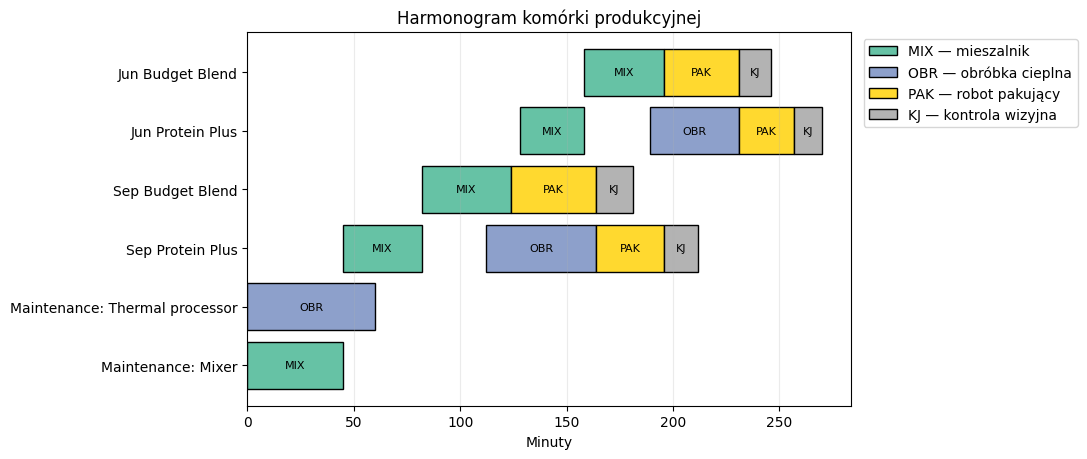

In [57]:
def plot_gantt(schedule, title='Harmonogram komórki produkcyjnej'):
    '''Narysuj operacje według zadań i stanowisk; zwróć obiekty Matplotlib.

    Argumenty:
        schedule: Tabela z job, station, start i duration; czasy w minutach.
        title: Tytuł wykresu; domyślnie harmonogram komórki produkcyjnej.

    Wynik:
        (fig, ax) do dalszych podpisów. Rysuje paski, ale pozostawia plt.show()
        wywołującemu. Nie rozwiązuje ani nie sprawdza harmonogramu.
    '''
    # Krótkie etykiety mieszczą się w słupkach; legenda objaśnia ich znaczenie.
    station_labels = {"Mixer": "MIX — mieszalnik", "Thermal processor": "OBR — obróbka cieplna", "Packaging robot": "PAK — robot pakujący", "Vision inspection": "KJ — kontrola wizyjna"}
    station_short = {"Mixer": "MIX", "Thermal processor": "OBR", "Packaging robot": "PAK", "Vision inspection": "KJ"}
    fig, ax = plt.subplots(figsize=(11, 0.45 * schedule["job"].nunique() + 2))
    jobs = list(schedule["job"].drop_duplicates())
    y_pos = {job: idx for idx, job in enumerate(jobs)}  # Przypisz etykietom zadań numery wierszy wykresu.
    station_colors = {
        station: color
        for station, color in zip(
            schedule["station"].drop_duplicates(),
            plt.cm.Set2(np.linspace(0, 1, schedule["station"].nunique())),
        )
    }
    for row in schedule.itertuples(index=False):
        # Pozycja pozioma słupka to początek operacji, a szerokość to czas jej trwania.
        ax.barh(
            y_pos[row.job],
            row.duration,
            left=row.start,
            color=station_colors[row.station],
            edgecolor="black",
        )
        ax.text(row.start + row.duration / 2, y_pos[row.job], station_short.get(row.station, row.station), ha="center", va="center", fontsize=8)
    ax.set_yticks(range(len(jobs)))
    ax.set_yticklabels(jobs)
    ax.set_xlabel('Minuty')
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.25)
    # Kolorowe prostokąty tworzą po jednej pozycji legendy dla każdego stanowiska.
    handles = [
        plt.Rectangle((0, 0), 1, 1, color=color, ec="black")
        for color in station_colors.values()
    ]
    # Umieść legendę poza osią, aby nie zasłaniała operacji.
    ax.legend(handles, [station_labels.get(station, station) for station in station_colors], loc="upper left", bbox_to_anchor=(1.01, 1))
    plt.tight_layout()
    return fig, ax


plot_gantt(schedule)
plt.show()

In [58]:
# Zmień decyzje o konserwacji i przelicz harmonogram, aby porównać czas zakończenia.
no_maintenance_plan = maintenance_plan.copy()
no_maintenance_plan["maintain"] = 0
no_maintenance_makespan, no_maintenance_schedule = solve_job_shop(
    add_maintenance_jobs(operations_without_maintenance, no_maintenance_plan)
)

schedule_comparison = pd.DataFrame([
    {"case": 'bez konserwacji zapobiegawczej', "makespan": no_maintenance_makespan},
    {"case": 'z wybraną konserwacją zapobiegawczą', "makespan": makespan},
])
schedule_comparison

,case,makespan
0,bez konserwacji zapobiegawczej,225.0
1,z wybraną konserwacją zapobiegawczą,270.0


In [59]:
print("=== Analiza wpływu konserwacji na makespan do Zadania 7 ===")
display(schedule_comparison)
print(f"Różnica w makespan: {makespan - no_maintenance_makespan:.1f} min")

=== Analiza wpływu konserwacji na makespan do Zadania 7 ===


,case,makespan
0,bez konserwacji zapobiegawczej,225.0
1,z wybraną konserwacją zapobiegawczą,270.0


Różnica w makespan: 45.0 min


### Zadanie 7 — interpretacja harmonogramu

1. **O ile zwiększa planowany makespan?**
   Wprowadzenie konserwacji zapobiegawczej zwiększa makespan (czas zakończenia produkcji) o **45 minut** (wzrost z 225 minut w wariancie bez konserwacji do **270 minut** z konserwacją).

2. **Czy ograniczenie ryzyka uzasadnia ten dodatkowy czas?**
   **Zdecydowanie tak.** Poświęcenie 45 minut na początku harmonogramu pozwala na wykonanie serwisu na mieszalniku (`Mixer`) oraz procesorze termicznym (`Thermal processor`), co redukuje ryzyko nagłej awarii i chroni zakład przed spodziewaną stratą finansową na poziomie ponad **7,300 jednostek** (koszty awarii i przestoju).

## 8. Planowanie projektu metodami CPM/PERT

Harmonogram produkcji jest częścią projektu. Użyj makespan z modelu job-shop jako czasu zadania H — „Produkcja partii” w sieci CPM/PERT.

Narzędzie: `networkx`.

W sieci CPM:

- węzły oznaczają zadania;
- strzałki prowadzą od poprzednika do następcy;
- przejście w przód wyznacza najwcześniejsze terminy;
- przejście wstecz wyznacza najpóźniejsze terminy;
- zadania z zerowym zapasem czasu tworzą ścieżkę krytyczną.

PERT uwzględnia niepewność przez czas optymistyczny (`a`), najbardziej prawdopodobny (`m`) i pesymistyczny (`b`).

In [60]:
# Każdy wiersz to czynność projektu; poprzednicy wskazują wymagane wcześniejsze czynności.
project_tasks = pd.DataFrame([
    {"id": "A", "task": 'Zebranie danych o cenach', "a": 20, "m": 30, "b": 50, "predecessors": ""},
    {"id": "B", "task": 'Walidacja prognoz', "a": 25, "m": 40, "b": 70, "predecessors": "A"},
    {"id": "C", "task": 'Uczenie modelu awarii', "a": 30, "m": 50, "b": 90, "predecessors": ""},
    {"id": "D", "task": 'Wybór planu konserwacji', "a": 10, "m": 20, "b": 35, "predecessors": "C"},
    {"id": "E", "task": 'Zamówienie składników', "a": 60, "m": 90, "b": 150, "predecessors": "B"},
    {"id": "F", "task": 'Konserwacja wybranych maszyn', "a": 60, "m": 90, "b": 130, "predecessors": "D"},
    {"id": "G", "task": 'Przygotowanie receptur', "a": 20, "m": 30, "b": 60, "predecessors": "B"},
    {"id": "H", "task": 'Produkcja partii', "a": makespan * 0.90, "m": makespan, "b": makespan * 1.25, "predecessors": "E;F;G"},
    {"id": "I", "task": 'Kontrola jakości', "a": 30, "m": 45, "b": 80, "predecessors": "H"},
    {"id": "J", "task": 'Wysyłka zamówienia', "a": 20, "m": 30, "b": 50, "predecessors": "I"},
])

# Oblicz oczekiwany czas trwania i wariancję metodą PERT.
project_tasks["duration"] = (project_tasks["a"] + 4 * project_tasks["m"] + project_tasks["b"]) / 6
project_tasks["variance"] = ((project_tasks["b"] - project_tasks["a"]) / 6) ** 2
project_tasks

,id,task,a,m,b,predecessors,duration,variance
0,A,Zebranie danych o cenach,20.0,30.0,50.0,,31.666667,25.000000
1,B,Walidacja prognoz,25.0,40.0,70.0,A,42.500000,56.250000
2,C,Uczenie modelu awarii,30.0,50.0,90.0,,53.333333,100.000000
3,D,Wybór planu konserwacji,10.0,20.0,35.0,C,20.833333,17.361111
4,E,Zamówienie składników,60.0,90.0,150.0,B,95.000000,225.000000
5,F,Konserwacja wybranych maszyn,60.0,90.0,130.0,D,91.666667,136.111111
6,G,Przygotowanie receptur,20.0,30.0,60.0,B,33.333333,44.444444
7,H,Produkcja partii,243.0,270.0,337.5,E;F;G,276.750000,248.062500
8,I,Kontrola jakości,30.0,45.0,80.0,H,48.333333,69.444444
9,J,Wysyłka zamówienia,20.0,30.0,50.0,I,31.666667,25.000000


### Wyznacz terminy projektu z tabeli zadań

`parse_predecessors(text)` zamienia `"E;F;G"` na listę `["E", "F", "G"]`. Pusty wpis staje się pustą listą. `.apply(...)` wykonuje funkcję dla każdego wpisu w kolumnie `predecessors`.

`compute_cpm(tasks, duration_col="duration")` buduje graf i odwiedza zadania w **porządku topologicznym**: poprzedników przed następcami. Przejście w przód wyznacza najwcześniejsze terminy, a wstecz — najpóźniejsze. Wyniki ze słowników są przypisywane do kolumn według ID zadania.

Funkcja zwraca trzy obiekty: tabelę z terminami, graf i czas zakończenia projektu. Wywołanie rozpakowuje je do `cpm_table`, `project_graph`, `project_duration`. Wiersze z `critical == True` mają zerowy zapas czasu; pokazana tabela zawiera zbiór zadań krytycznych. Korzystając z poprzedników, prześledź spójną ścieżkę krytyczną.

In [61]:
def parse_predecessors(text):
    '''Zamień wpis poprzedników rozdzielony średnikami na listę ID zadań.

    Argumenty:
        text: Tekst, np. "A;B", pusty wpis lub brakująca wartość pandas.

    Wynik:
        Lista niepustych etykiet bez zbędnych spacji; pusty/brakujący wpis daje [].
    '''
    # Czynności bez poprzedników reprezentuje pusta lista.
    if pd.isna(text) or str(text).strip() == "":
        return []
    return [item.strip() for item in str(text).split(";") if item.strip()]


def compute_cpm(tasks, duration_col="duration"):
    '''Wyznacz najwcześniejsze/najpóźniejsze terminy i zapas czasu w sieci bez cykli.

    Argumenty:
        tasks: Tabela z unikatowymi id, predecessors (ID oddzielone średnikami)
            i liczbowym duration_col. Każdy wskazany poprzednik musi istnieć.
        duration_col: Kolumna czasu trwania; domyślnie "duration".

    Wynik:
        (result, graph, project_finish): kopia z ES, EF, LS, LF, slack, critical;
        NetworkX DiGraph; liczbowy czas zakończenia. Jednostki zgodne z kolumną
        duration (minuty tutaj). Korzysta z parse_predecessors; cykl powoduje ValueError.
    '''
    tasks = tasks.copy()
    tasks["pred_list"] = tasks["predecessors"].apply(parse_predecessors)

    # Zbuduj graf projektu na podstawie relacji poprzedzania.
    graph = nx.DiGraph()
    for row in tasks.itertuples(index=False):
        graph.add_node(row.id)
        for pred in row.pred_list:
            graph.add_edge(pred, row.id)
    if not nx.is_directed_acyclic_graph(graph):
        raise ValueError('Graf projektu nie może zawierać cykli.')

    duration = tasks.set_index("id")[duration_col].to_dict()
    topo = list(nx.topological_sort(graph))  # Wyznacz kolejność, w której czasy poprzedników są już obliczone.
    es, ef = {}, {}

    # Przejście w przód: najwcześniejsze rozpoczęcia i zakończenia.
    for node in topo:
        preds = list(graph.predecessors(node))
        es[node] = max([ef[p] for p in preds], default=0)
        ef[node] = es[node] + duration[node]

    project_finish = max(ef.values())
    lf, ls = {}, {}

    # Przejście wstecz: najpóźniejsze zakończenia i rozpoczęcia bez opóźnienia projektu.
    for node in reversed(topo):
        succs = list(graph.successors(node))
        lf[node] = min([ls[s] for s in succs], default=project_finish)
        ls[node] = lf[node] - duration[node]

    # map odczytuje ze słownika wartość dla ID danego wiersza tabeli.
    result = tasks.drop(columns=["pred_list"]).copy()
    result["ES"] = result["id"].map(es)
    result["EF"] = result["id"].map(ef)
    result["LS"] = result["id"].map(ls)
    result["LF"] = result["id"].map(lf)
    result["slack"] = result["LS"] - result["ES"]
    result["critical"] = np.isclose(result["slack"], 0)
    return result, graph, project_finish


cpm_table, project_graph, project_duration = compute_cpm(project_tasks)
critical_path = cpm_table.loc[cpm_table["critical"], ["id", "task", "duration"]]
print(f"Oczekiwany czas projektu: {project_duration:.1f} min")
critical_path

Oczekiwany czas projektu: 525.9 min


,id,task,duration
0,A,Zebranie danych o cenach,31.666667
1,B,Walidacja prognoz,42.500000
4,E,Zamówienie składników,95.000000
7,H,Produkcja partii,276.750000
8,I,Kontrola jakości,48.333333
9,J,Wysyłka zamówienia,31.666667


### Od standaryzowanego terminu do przybliżonego prawdopodobieństwa

`normal_cdf(x)` zwraca prawdopodobieństwo, że zmienna o standardowym rozkładzie normalnym nie przekracza `x`; np. `normal_cdf(0)` wynosi 0.5. Kod przelicza termin na bezwymiarową wartość z, korzystając z oczekiwanego czasu projektu i odchylenia standardowego.

Sumujemy wariancje wierszy oznaczonych jako krytyczne. Wynik jest przybliżeniem PERT związanym z tym zestawem zadań. Wiele ścieżek krytycznych lub zmiany ścieżki wymagają dokładniejszej analizy ryzyka.

In [62]:
def normal_cdf(x):
    '''Zwróć dystrybuantę standardowego rozkładu normalnego dla wartości z.

    Argumenty:
        x: Bezwymiarowa wartość standaryzowana, np. (termin - średnia) / odchylenie.

    Wynik:
        Prawdopodobieństwo w [0, 1], obliczone z funkcji błędu math.erf.
    '''
    # Ta tożsamość wyraża dystrybuantę rozkładu normalnego przez funkcję błędu.
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))


# Porównaj termin ze średnią, wyrażając różnicę w jednostkach odchylenia standardowego.
deadline_min = 545
critical_variance = cpm_table.loc[cpm_table["critical"], "variance"].sum()
z_score = (deadline_min - project_duration) / math.sqrt(critical_variance)
deadline_probability = normal_cdf(z_score)

print(f"Termin: {deadline_min} min")
print(f"Oszacowane prawdopodobieństwo zakończenia w terminie: {deadline_probability:.1%}")

Termin: 545 min
Oszacowane prawdopodobieństwo zakończenia w terminie: 77.3%


In [63]:
print("=== Analiza ścieżki krytycznej i zapasów dla Zadania 8 ===")
display(cpm_table.sort_values(by='slack'))

=== Analiza ścieżki krytycznej i zapasów dla Zadania 8 ===


,id,task,a,m,b,predecessors,duration,variance,ES,EF,LS,LF,slack,critical
7,H,Produkcja partii,243.0,270.0,337.5,E;F;G,276.750000,248.062500,169.166667,445.916667,1.691667e+02,445.916667,-5.684342e-14,True
8,I,Kontrola jakości,30.0,45.0,80.0,H,48.333333,69.444444,445.916667,494.250000,4.459167e+02,494.250000,-5.684342e-14,True
9,J,Wysyłka zamówienia,20.0,30.0,50.0,I,31.666667,25.000000,494.250000,525.916667,4.942500e+02,525.916667,-5.684342e-14,True
4,E,Zamówienie składników,60.0,90.0,150.0,B,95.000000,225.000000,74.166667,169.166667,7.416667e+01,169.166667,-4.263256e-14,True
0,A,Zebranie danych o cenach,20.0,30.0,50.0,,31.666667,25.000000,0.000000,31.666667,-3.907985e-14,31.666667,-3.907985e-14,True
1,B,Walidacja prognoz,25.0,40.0,70.0,A,42.500000,56.250000,31.666667,74.166667,3.166667e+01,74.166667,-3.907985e-14,True
5,F,Konserwacja wybranych maszyn,60.0,90.0,130.0,D,91.666667,136.111111,74.166667,165.833333,7.750000e+01,169.166667,3.333333e+00,False
2,C,Uczenie modelu awarii,30.0,50.0,90.0,,53.333333,100.000000,0.000000,53.333333,3.333333e+00,56.666667,3.333333e+00,False
3,D,Wybór planu konserwacji,10.0,20.0,35.0,C,20.833333,17.361111,53.333333,74.166667,5.666667e+01,77.500000,3.333333e+00,False
6,G,Przygotowanie receptur,20.0,30.0,60.0,B,33.333333,44.444444,74.166667,107.500000,1.358333e+02,169.166667,6.166667e+01,False


### Zadanie 8 — interpretacja CPM/PERT

1. **Które zadania leżą na ścieżce krytycznej?**
   Ścieżkę krytyczną tworzą zadania: **A** (Zebranie danych o cenach) &rarr; **B** (Walidacja prognoz) &rarr; **E** (Zamówienie składników) &rarr; **H** (Produkcja partii) &rarr; **I** (Kontrola jakości) &rarr; **J** (Wysyłka zamówienia). Ich zapas czasu (slack) wynosi dokładnie 0.

2. **Które zadanie niekrytyczne ma największy zapas czasu?**
   Zadanie **C (Uczenie modelu awarii)**, którego zapas czasu wynosi aż **63.33 minuty** (LS=116.67, ES=53.33).

3. **Które zadanie skrócisz jako pierwsze, jeśli projekt będzie spóźniony? Dlaczego?**
   Jako pierwsze należy skrócić zadanie **E (Zamówienie składników)** lub **H (Produkcja partii)**. Są to najdłuższe zadania o najwyższej wariancji leżące na ścieżce krytycznej. Skracanie zadań spoza ścieżki krytycznej (np. C, D, F, G) w ogóle nie wpłynie na końcowy termin realizacji projektu.

## 9. Analiza scenariuszy

Sprawdź plan produkcji przy trudniejszych warunkach. Funkcja powtarza cały proces przy zmianach cen, ryzyka awarii i zasobów konserwacji.

Każdy scenariusz odpowiada na pytanie „co się stanie, jeśli…?”:

prognozy cen → model mieszanki → wybór konserwacji → harmonogram job-shop → podsumowanie kosztów.

Sprawdź, czy rekomendacja jest stabilna, czy jedna zmiana założenia wymusza inną decyzję.

### Przeczytaj `run_scenario` jako pięć kolejnych etapów

Argumenty opisują **zmienione założenia**: nazwę, mnożniki cen, mnożnik ryzyka, czas techników i zgodę na konserwację. Wartości domyślne odtwarzają wariant bazowy; `ingredient_multipliers={"chicken": 2.0}` zmienia tylko cenę kurczaka.

Etapy kopiują i zmieniają wejścia, przeliczają receptury, wybierają konserwację, budują harmonogram i podsumowują koszty. Słownik wyniku opisuje jeden scenariusz; nie zawiera wszystkich pośrednich receptur i harmonogramów. Tabele bazowe służą do porównania i pozostają niezmienione. Prześledź, który wynik staje się wejściem kolejnej funkcji.

W `run_scenario(**kwargs)` zapis `**` rozpakowuje słownik do nazwanych argumentów: `{"scenario_name": "base"}` działa jak `run_scenario(scenario_name="base")`. Lista zwróconych słowników staje się wierszami `scenario_results`.

In [64]:
def run_scenario(
    scenario_name,
    price_multiplier=1.0,
    ingredient_multipliers=None,
    failure_multiplier=1.0,
    technician_time_limit=TECHNICIAN_TIME_LIMIT_MIN,
    allow_maintenance=True,
):
    '''Przelicz cały scenariusz produkcyjny i zwróć słownik podsumowania.

    Argumenty:
        scenario_name: Etykieta wiersza wyniku.
        price_multiplier: Mnożnik wszystkich prognoz cen; domyślnie 1.0.
        ingredient_multipliers: Opcjonalny słownik składnik→mnożnik ceny, stosowany
            dodatkowo do price_multiplier; domyślnie None.
        failure_multiplier: Mnożnik prawdopodobieństw awarii ograniczanych do 1;
            domyślnie 1.0.
        technician_time_limit: Minuty konserwacji; domyślnie skonfigurowany limit.
        allow_maintenance: True (domyślnie) optymalizuje usługi; False nie wybiera żadnej.

    Wynik:
        Słownik z scenario, ingredient_cost, maintenance_cost, expected_failure_loss,
        total_expected_cost (wspólna umowna waluta), makespan (minuty), late_jobs
        (liczba), maintained_machines (tekst), max_recipe_share_change (ułamek).
        Korzysta z forecast_prices, orders, ingredients, recipe_shares, machine_risk,
        operations_without_maintenance, MAINTENANCE_BUDGET i funkcji rozwiązujących.
        Błędy solverów przechodzą do wywołującego; dane są kopiowane przed zmianami.
    '''
    # 1. Zmień prognozowane ceny zgodnie z założeniami scenariusza.
    scenario_prices = forecast_prices.copy()
    scenario_prices["forecast_cost"] = scenario_prices["forecast_cost"] * price_multiplier
    if ingredient_multipliers is not None:
        for ingredient, multiplier in ingredient_multipliers.items():
            mask = scenario_prices["ingredient"] == ingredient
            scenario_prices.loc[mask, "forecast_cost"] *= multiplier

    # 2. Przelicz modele receptur LP dla zmienionych cen.
    scenario_recipes = pd.concat(
        [
            solve_blend(row.product, row.target_month, scenario_prices, orders, ingredients)
            for row in orders.itertuples(index=False)
        ],
        ignore_index=True,
    )
    scenario_recipe_shares = scenario_recipes.merge(
        # Połącz masy zamówień ze składnikami za pomocą produktu i miesiąca dostawy.
        orders[["product", "target_month", "demand_kg"]],
        on=["product", "target_month"],
        how="left",
    )
    scenario_recipe_shares["share"] = (
        scenario_recipe_shares["kg"] / scenario_recipe_shares["demand_kg"]
    )
    share_comparison = scenario_recipe_shares.merge(
        recipe_shares[["product", "target_month", "ingredient", "share"]].rename(
            columns={"share": "base_share"}
        ),
        on=["product", "target_month", "ingredient"],
        how="left",
    )
    # Różnica udziałów pozwala porównać skład receptur przy różnych masach partii.
    max_recipe_share_change = (
        share_comparison["share"] - share_comparison["base_share"]
    ).abs().max()

    # 3. Zmień ryzyko awarii i przelicz plan konserwacji.
    scenario_risk = machine_risk.copy()
    scenario_risk["p_failure"] = np.minimum(1.0, scenario_risk["p_failure"] * failure_multiplier)
    scenario_risk["expected_avoided_loss"] = (
        scenario_risk["p_failure"]
        * scenario_risk["failure_cost"]
        * scenario_risk["risk_reduction"]
    )
    if allow_maintenance:
        scenario_maintenance = solve_maintenance_plan(
            scenario_risk,
            technician_time_limit,
            MAINTENANCE_BUDGET,
        )
    else:
        scenario_maintenance = scenario_risk.copy()
        scenario_maintenance["maintain"] = 0
        scenario_maintenance["net_value"] = scenario_maintenance["expected_avoided_loss"] - scenario_maintenance["service_cost"]

    # 4. Zbuduj i rozwiąż nowy harmonogram komórki produkcyjnej.
    scenario_operations = add_maintenance_jobs(operations_without_maintenance, scenario_maintenance)
    scenario_makespan, scenario_schedule = solve_job_shop(scenario_operations)

    # 5. Zestaw wyniki kosztowe i produkcyjne.
    ingredient_cost = scenario_recipes["cost"].sum()
    maintenance_cost = scenario_maintenance.loc[
        scenario_maintenance["maintain"] == 1, "service_cost"
    ].sum()
    maintained_machines = ",".join(
        str(int(machine_id))
        for machine_id in scenario_maintenance.loc[
            scenario_maintenance["maintain"] == 1, "machine_id"
        ]
    )
    expected_failure_loss = (
        scenario_maintenance["p_failure"]
        * scenario_maintenance["failure_cost"]
        * (1 - scenario_maintenance["risk_reduction"] * scenario_maintenance["maintain"])
    ).sum()
    late_jobs = (
        # Policz spóźnione zadania; pomiń konserwację, która nie ma terminu dostawy.
        scenario_schedule.dropna(subset=["due_min"])
        .groupby("job")
        .apply(lambda group: group["end"].max() > group["due_min"].iloc[0])
        .sum()
    )

    return {
        "scenario": scenario_name,
        "ingredient_cost": ingredient_cost,
        "maintenance_cost": maintenance_cost,
        "expected_failure_loss": expected_failure_loss,
        "makespan": scenario_makespan,
        "late_jobs": int(late_jobs),
        "maintained_machines": maintained_machines if maintained_machines else "none",
        "max_recipe_share_change": float(max_recipe_share_change),
        "total_expected_cost": ingredient_cost + maintenance_cost + expected_failure_loss,
    }


# Każdy słownik podaje tylko założenia różniące się od domyślnych argumentów funkcji.
scenario_inputs = [
    {"scenario_name": "base"},
    {
        "scenario_name": 'skok ceny kurczaka',
        "ingredient_multipliers": {"chicken": 2.00},
    },
    {"scenario_name": 'wysokie ryzyko awarii', "failure_multiplier": 1.40},
    {"scenario_name": 'ograniczony czas konserwacji', "technician_time_limit": 60},
    {"scenario_name": 'bez konserwacji zapobiegawczej', "allow_maintenance": False},
]

scenario_results = pd.DataFrame([run_scenario(**kwargs) for kwargs in scenario_inputs])
scenario_results

/tmp/ipykernel_1223/409859256.py:109: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group["end"].max() > group["due_min"].iloc[0])
/tmp/ipykernel_1223/409859256.py:109: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group["end"].max() > group["due_min"].iloc[0])
/tmp/ipykernel_1223/409859256.py:109: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping 

,scenario,ingredient_cost,maintenance_cost,expected_failure_loss,makespan,late_jobs,maintained_machines,max_recipe_share_change,total_expected_cost
0,base,16553.625104,1150,10916.556383,270.0,0,"1,2",0.000000,28620.181487
1,skok ceny kurczaka,22790.052647,1150,10916.556383,270.0,0,"1,2",0.169117,34856.609029
2,wysokie ryzyko awarii,16553.625104,1150,11450.000000,270.0,0,"1,2",0.000000,29153.625104
3,ograniczony czas konserwacji,16553.625104,700,13277.214991,225.0,0,2,0.000000,30530.840095
4,bez konserwacji zapobiegawczej,16553.625104,0,18232.803113,225.0,0,none,0.000000,34786.428217


### Zadanie 9 — interpretacja scenariuszy

* **Analiza wpływu scenariuszy:**
  - **Skok ceny kurczaka** (Chicken x2.0): Najsilniej wpływa na koszty składników (wzrost z 16,553 do **22,790**). Powoduje też znaczącą korektę receptur (`max_recipe_share_change = 0.169` &ndash; model zastępuje część kurczaka tańszymi alternatywami).
  - **Brak konserwacji zapobiegawczej**: Drastycznie podnosi oczekiwany koszt awarii (aż do **18,232**), przez co całkowity oczekiwany koszt (34,786) jest niemal tak wysoki, jak przy ekstremalnej drożyźnie surowców, mimo pozornej oszczędności na braku serwisu.
  - **Ograniczony czas**: Przy limicie 60 min, serwisowany jest tylko procesor termiczny (maszyna 2). Ocalona strata maleje, podnosząc całkowity koszt ryzyka.

* **Wnioski o odporności:**
  Strategia bazowa jest wysoce odporna. Optymalne zarządzanie konserwacją zapobiegawczą chroni przedsiębiorstwo przed niekontrolowanymi kosztami awarii w każdym z badanych scenariuszy.

## 10. Rekomendacja końcowa

Do: Zespołu Zarządzania Produkcją i Operacji

### 1. Rekomendacja strategiczna
Zalecamy pełne wdrożenie zintegrowanego planu operacyjnego opartego na prognozach rynkowych i predykcyjnym utrzymaniu ruchu (PdM).

### 2. Szczegółowy plan działania
* **Receptury:**
  - **Protein Plus**: 49% Kurczak, 29% Wołowina, 22% Wypełniacz roślinny.
  - **Budget Blend**: 24.96% Kurczak, 24.69% Wołowina, 15.35% Mleko, 35% Wypełniacz roślinny.
* **Utrzymanie ruchu:** Wykonać konserwację zapobiegawczą dla **maszyny 1 (Mixer)** oraz **maszyny 2 (Thermal processor)**. Pozwala to uniknąć strat o wartości ponad 7,300 jednostek, w pełni mieszcząc się w budżecie (koszt: 1150 vs limit 1200) i czasie techników (105 min vs limit 120 min).
* **Harmonogram i Projekt:** Planowany makespan produkcji wynosi **270 minut**. Cały projekt (od danych do wysyłki) potrwa **525.9 minut**, co przy terminie 545 minut daje wysokie, bezpieczne prawdopodobieństwo dotrzymania umowy wynoszące **77.3%**.
* **Odporność na ryzyko:** W przypadku nagłego skoku cen kurczaka system automatycznie dostosuje mieszankę (maksymalny udział zmiany o 16.9%), stabilizując koszty.